# Данные

### Описание

**Название**: "Yelp Dataset"

**Источник**: Kaggle

**Ссылка**: https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset

**Краткое описание**: набор данных оценивания пользователями различных заведений. Соответственно, здесь user - это обычные люди, item - какой-либо бизнес (заведение).

### Загрузка данных

In [204]:
import polars as pl

In [205]:
business_data = pl.read_ndjson("data/yelp_academic_dataset_business.json", infer_schema_length=None)
checkin_data = pl.read_ndjson("data/yelp_academic_dataset_checkin.json")
review_data = pl.read_ndjson("data/yelp_academic_dataset_review.json")
tip_data = pl.read_ndjson("data/yelp_academic_dataset_tip.json")
user_data = pl.read_ndjson("data/yelp_academic_dataset_user.json")

### Посмотрим, что внутри каждого из наборов

In [206]:
business_data.columns

['business_id',
 'name',
 'address',
 'city',
 'state',
 'postal_code',
 'latitude',
 'longitude',
 'stars',
 'review_count',
 'is_open',
 'attributes',
 'categories',
 'hours']

Интерпретация

- `business_id` - `str` - уникальный идентификатор заведения.
- `name` - `str` - название заведения.
- `address` - `str` - адрес (улица).
- `city` - `str` - город.
- `state` - `str` - штат (2-буквенный код).
- `postal_code` - `str` - почтовый индекс.
- `latitude` - `f64` - широта (географическая координата).
- `longitude` - `f64` - долгота (географическая координата).
- `stars` - `f64` - средний рейтинг заведения (1.0–5.0).
- `review_count` - `i64` - общее число отзывов о заведении.
- `is_open` - `i64` - статус: 1 - работает, 0 - закрыто.
- `attributes` - `struct[33]` - словарь опциональных характеристик заведения (ценовой диапазон, Wi-Fi, парковка, алкоголь и т.д.).
- `categories` - `str` - список категорий заведения через запятую (например, «Restaurants, Italian, Pizza»).
- `hours` - `struct[7]` - словарь с часами работы по дням недели.

In [207]:
checkin_data.columns

['business_id', 'date']

Интерпретация

- `business_id` - `str` - уникальный идентификатор заведения
- `date` - `str` - строка, содержащая **список отметок о посещениях (чекинах)**, разделённых запятыми; каждая отметка в формате `YYYY-MM-DD HH:MM:SS`.

In [208]:
review_data.columns

['review_id',
 'user_id',
 'business_id',
 'stars',
 'useful',
 'funny',
 'cool',
 'text',
 'date']

Интерпретация

- **`review_id`** (`str`) - уникальный идентификатор отзыва (22 символа).
- **`user_id`** (`str`) - уникальный идентификатор пользователя, написавшего отзыв (22 символа); ключ для связи с `user.json`.
- **`business_id`** (`str`) - уникальный идентификатор заведения, о котором написан отзыв (22 символа); ключ для связи с `business.json`.
- **`stars`** (`i64`) - оценка, поставленная пользователем (целое число от 1 до 5).
- **`date`** (`str`) - дата написания отзыва в формате `YYYY-MM-DD`.
- **`text`** (`str`) - полный текст отзыва.
- **`useful`** (`i64`) - количество голосов «полезно», полученных этим отзывом.
- **`funny`** (`i64`) - количество голосов «смешно», полученных этим отзывом.
- **`cool`** (`i64`) - количество голосов «круто», полученных этим отзывом.

In [209]:
tip_data.columns

['user_id', 'business_id', 'text', 'date', 'compliment_count']

Интерпретация

- `user_id` (`str`) - идентификатор пользователя, оставившего совет.
- `business_id` (`str`) - идентификатор заведения.
- `text` (`str`) - текст совета (в работе не используется).
- `date` (`str`) - дата и время в формате `YYYY-MM-DD HH:MM:SS`.
- `compliment_count` (`i64`) - число комплиментов, полученных советом.

In [210]:
user_data.columns

['user_id',
 'name',
 'review_count',
 'yelping_since',
 'useful',
 'funny',
 'cool',
 'elite',
 'friends',
 'fans',
 'average_stars',
 'compliment_hot',
 'compliment_more',
 'compliment_profile',
 'compliment_cute',
 'compliment_list',
 'compliment_note',
 'compliment_plain',
 'compliment_cool',
 'compliment_funny',
 'compliment_writer',
 'compliment_photos']

Интерпретация

- `user_id` (`str`) - уникальный идентификатор пользователя (22 символа).
- `name` (`str`) - имя пользователя.
- `review_count` (`i64`) - общее число отзывов, написанных пользователем.
- `yelping_since` (`str`) - дата регистрации на Yelp в формате `YYYY-MM`.
- `useful` (`i64`) - суммарное число голосов «полезно», полученных отзывами пользователя.
- `funny` (`i64`) - суммарное число голосов «смешно», полученных отзывами пользователя.
- `cool` (`i64`) - суммарное число голосов «круто», полученных отзывами пользователя.
- `elite` (`str`) - годы, в которые пользователь был участником программы Yelp Elite, через запятую (например, `"2015,2016,2017"`); пустая строка, если никогда не был.
- `friends` (`str`) - список `user_id` друзей через запятую.
- `fans` (`i64`) - число подписчиков (фанатов) пользователя.
- `average_stars` (`f64`) - средняя оценка, которую ставит пользователь (1.0–5.0).
- `compliment_hot` (`i64`) - число полученных комплиментов «hot».
- `compliment_more` (`i64`) - число полученных комплиментов «more».
- `compliment_profile` (`i64`) - число полученных комплиментов «profile».
- `compliment_cute` (`i64`) - число полученных комплиментов «cute».
- `compliment_list` (`i64`) - число полученных комплиментов «list».
- `compliment_note` (`i64`) - число полученных комплиментов «note».
- `compliment_plain` (`i64`) - число полученных комплиментов «plain».
- `compliment_cool` (`i64`) - число полученных комплиментов «cool».
- `compliment_funny` (`i64`) - число полученных комплиментов «funny».
- `compliment_writer` (`i64`) - число полученных комплиментов «writer».
- `compliment_photos` (`i64`) - число полученных комплиментов «photos».

### Взаимодействия

- **Основное взаимодействие - отзыв** (`review.json`): пользователь посетил заведение и поставил
  оценку от 1 до 5. Из отзывов строится матрица пользователь х заведение.
- **Совет** (`tip.json`) - короткое сообщение о заведении без оценки, то есть implicit feedback.
- **Чекин** (`checkin.json`) - отметка о посещении без идентификатора пользователя. Характеризует
  популярность заведения и может использоваться только как признак объекта.
- `business.json` и `user.json` - метаданные объектов и пользователей.

### Объём данных

- **Исходный объём:** 6 990 280 отзывов, 1 987 929 пользователей, 150 346 заведений;
  период 16.02.2005 - 19.01.2022. Разреженность матрицы «пользователь × заведение» - 99,9977 %.
  Дополнительно: 908 915 советов (tip) и 13 356 875 чекинов по 131 930 заведениям.
- **Итоговый объём**:
  … взаимодействий, … пользователей, … заведений; штат …, категория Restaurants, k-core с порогом … .

# Постановка задачи

**Что рекомендуем.** 10 заведений, которые пользователь ещё не оценивал

**Взаимодействие.** Отзыв с оценкой от 1 до 5 звёзд

**Релевантный объект.** Заведение, которое пользователь в тестовом периоде оценил на 4 или 5 звёзд

# EDA


### Подготовка к анализу

Из таблицы отзывов выделяются только поля, необходимые для анализа взаимодействий (текст отзыва не нужен),
а строковая дата переводится в тип `datetime`

In [211]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")
pl.Config.set_tbl_rows(30)

date_col = pl.col("date")
reviews = review_data.select(
    "user_id",
    "business_id",
    pl.col("stars").cast(pl.Float64),
    "useful",
    "funny",
    "cool",
    pl.coalesce(
        date_col.str.to_datetime("%Y-%m-%d %H:%M:%S", strict=False),
        date_col.str.to_datetime("%Y-%m-%d", strict=False),
    ).alias("date"),
)
reviews.head()

user_id,business_id,stars,useful,funny,cool,date
str,str,f64,i64,i64,i64,datetime[μs]
"""mh_-eMZ6K5RLWhZyISBhwA""","""XQfwVwDr-v0ZS3_CbbE5Xw""",3.0,0,0,0,2018-07-07 22:09:11
"""OyoGAe7OKpv6SyGZT5g77Q""","""7ATYjTIgM3jUlt4UM3IypQ""",5.0,1,0,1,2012-01-03 15:28:18
"""8g_iMtfSiwikVnbP2etR0A""","""YjUWPpI6HXG530lwP-fb2A""",3.0,0,0,0,2014-02-05 20:30:30
"""_7bHUi9Uuf5__HHc_Q8guQ""","""kxX2SOes4o-D3ZQBkiMRfA""",5.0,1,0,1,2015-01-04 00:01:03
"""bcjbaE6dDog4jkNY91ncLQ""","""e4Vwtrqf-wpJfwesgvdgxQ""",4.0,1,0,1,2017-01-14 20:54:15


### Общая статистика взаимодействий

Числа взаимодействий, пользователей и
заведений, а также периода наблюдений задают масштаб задачи, позволяют сравнить объём данных
с ограничениями задания (от 100 тыс. до 2 млн взаимодействий) и оценить разреженность матрицы. 
Чем она выше, тем меньше взаимодействий для kNN и тем важнее регуляризация в MF.

In [212]:
n_reviews = reviews.height
n_users = reviews["user_id"].n_unique()
n_items = reviews["business_id"].n_unique()
sparsity = 1 - n_reviews / (n_users * n_items)

print(f"Число отзывов:              {n_reviews:,}")
print(f"Уникальных пользователей:   {n_users:,}")
print(f"Уникальных заведений:       {n_items:,}")
print(f"Период:                     {reviews['date'].min()} - {reviews['date'].max()}")
print(f"Разреженность матрицы:      {sparsity:.6f} ({sparsity * 100:.4f}%)")
print()
print(f"Записей в business:         {business_data.height:,}")
print(f"Записей в user:             {user_data.height:,}")
print(f"Записей в tip:              {tip_data.height:,}")
print(f"Записей в checkin:          {checkin_data.height:,}")

Число отзывов:              6,990,280
Уникальных пользователей:   1,987,929
Уникальных заведений:       150,346
Период:                     2005-02-16 03:23:22 - 2022-01-19 19:48:45
Разреженность матрицы:      0.999977 (99.9977%)

Записей в business:         150,346
Записей в user:             1,987,897
Записей в tip:              908,915
Записей в checkin:          131,930


### Распределение оценок

Распределение показывает, насколько сбалансированы оценки и какая доля взаимодействий будет
считаться релевантной при оценке качества

shape: (5, 3)
┌───────┬─────────┬────────┐
│ stars ┆ count   ┆ share  │
│ ---   ┆ ---     ┆ ---    │
│ f64   ┆ u32     ┆ f64    │
╞═══════╪═════════╪════════╡
│ 1.0   ┆ 1069561 ┆ 0.153  │
│ 2.0   ┆ 544240  ┆ 0.0779 │
│ 3.0   ┆ 691934  ┆ 0.099  │
│ 4.0   ┆ 1452918 ┆ 0.2078 │
│ 5.0   ┆ 3231627 ┆ 0.4623 │
└───────┴─────────┴────────┘

Доля оценок 4–5 (релевантные взаимодействия): 0.6702


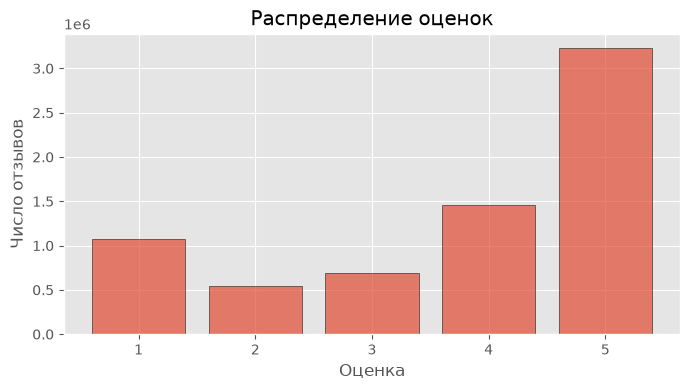

In [213]:
star_counts = (
    reviews.group_by("stars")
    .agg(pl.len().alias("count"))
    .sort("stars")
    .with_columns((pl.col("count") / pl.col("count").sum()).round(4).alias("share"))
)
print(star_counts)
print(f"\nДоля оценок 4–5 (релевантные взаимодействия): {(reviews['stars'] >= 4).mean():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(star_counts["stars"].to_numpy(), star_counts["count"].to_numpy(), edgecolor="black", alpha=0.7)
ax.set_xlabel("Оценка")
ax.set_ylabel("Число отзывов")
ax.set_title("Распределение оценок")
plt.tight_layout()
plt.show()

### Активность пользователей

Коллаборативные методы не могут построить качественные рекомендации для пользователей с одним-двумя
взаимодействиями, а при временном разбиении у пользователя должна остаться история и в train,
и в test. Поэтому распределение активности обосновывает последующую фильтрацию пользователей

Mean:    3.51636300894046
Std:     12.770877900860565
Median:  1.0

Доля пользователей с >=   2 отзывами: 0.4285
Доля пользователей с >=   3 отзывами: 0.2668
Доля пользователей с >=   5 отзывами: 0.1444
Доля пользователей с >=  10 отзывами: 0.0590
Доля пользователей с >=  20 отзывами: 0.0226


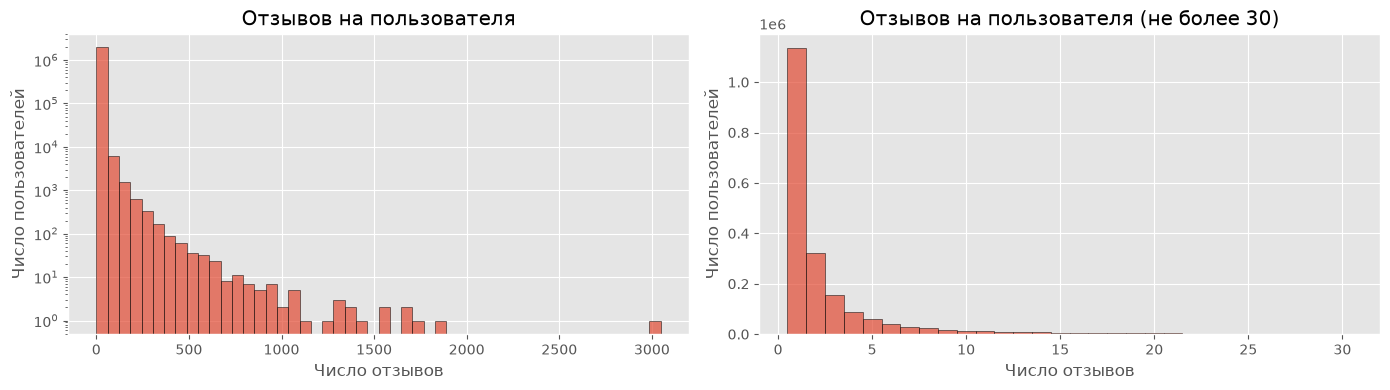

In [214]:
user_counts = reviews.group_by("user_id").agg(pl.len().alias("n_reviews"))["n_reviews"]

print("Mean:   ", user_counts.mean())
print("Std:    ", user_counts.std())
print("Median: ", user_counts.median())
print()
for t in [2, 3, 5, 10, 20]:
    print(f"Доля пользователей с >= {t:>3} отзывами: {(user_counts >= t).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(user_counts.to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Число отзывов")
axes[0].set_ylabel("Число пользователей")
axes[0].set_title("Отзывов на пользователя")
axes[0].set_yscale("log")

small = user_counts.filter(user_counts <= 30).to_numpy()
axes[1].hist(small, bins=np.arange(0.5, 31.5, 1), edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Число отзывов")
axes[1].set_ylabel("Число пользователей")
axes[1].set_title("Отзывов на пользователя (не более 30)")

plt.tight_layout()
plt.show()

### Популярность заведений

Если большая часть отзывов приходится на небольшую долю популярных заведений, модели склонны рекомендовать именно их,
а для редких объектов оценки сходства и эмбеддинги получаются ненадёжными. Это обосновывает порог
минимального числа взаимодействий для заведений

Mean:    46.49461907865856
Std:     124.5190605055779
Median:  15.0

Доля заведений с >=   5 отзывами: 1.0000
Доля заведений с >=  10 отзывами: 0.6736
Доля заведений с >=  20 отзывами: 0.4223
Доля заведений с >=  50 отзывами: 0.2007
Доля заведений с >= 100 отзывами: 0.1017


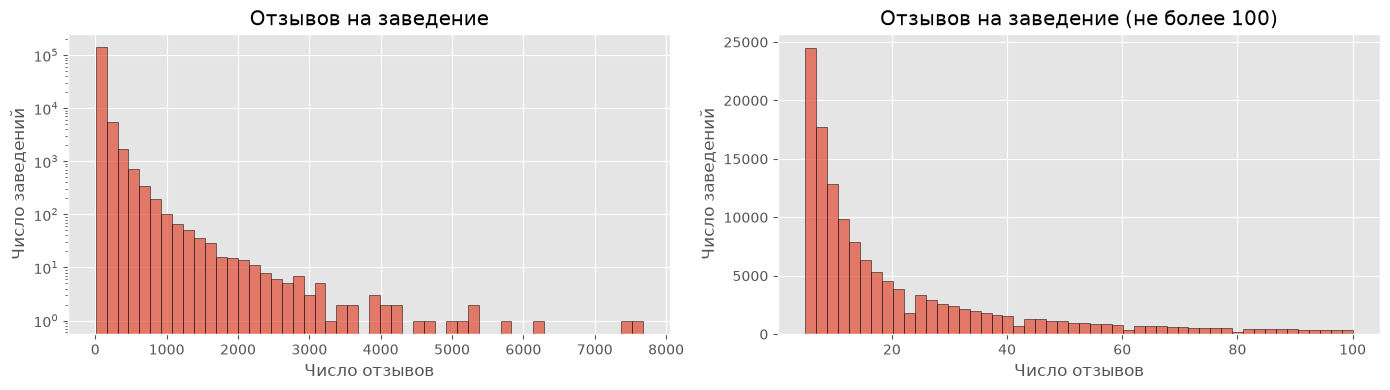

In [215]:
item_counts = reviews.group_by("business_id").agg(pl.len().alias("n_reviews"))["n_reviews"]

print("Mean:   ", item_counts.mean())
print("Std:    ", item_counts.std())
print("Median: ", item_counts.median())
print()
for t in [5, 10, 20, 50, 100]:
    print(f"Доля заведений с >= {t:>3} отзывами: {(item_counts >= t).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(item_counts.to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Число отзывов")
axes[0].set_ylabel("Число заведений")
axes[0].set_title("Отзывов на заведение")
axes[0].set_yscale("log")

small = item_counts.filter(item_counts <= 100).to_numpy()
axes[1].hist(small, bins=50, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Число отзывов")
axes[1].set_ylabel("Число заведений")
axes[1].set_title("Отзывов на заведение (не более 100)")

plt.tight_layout()
plt.show()

### Категории заведений

In [216]:
# Примеры исходных строк categories в business.json
print(business_data["categories"].drop_nulls().head(5).to_list())

['Doctors, Traditional Chinese Medicine, Naturopathic/Holistic, Acupuncture, Health & Medical, Nutritionists', 'Shipping Centers, Local Services, Notaries, Mailbox Centers, Printing Services', 'Department Stores, Shopping, Fashion, Home & Garden, Electronics, Furniture Stores', 'Restaurants, Food, Bubble Tea, Coffee & Tea, Bakeries', 'Brewpubs, Breweries, Food']


Уникальных категорий: 1,311
shape: (15, 3)
┌───────────────────────────┬────────────┬───────────┐
│ category                  ┆ n_business ┆ n_reviews │
│ ---                       ┆ ---        ┆ ---       │
│ str                       ┆ u32        ┆ u32       │
╞═══════════════════════════╪════════════╪═══════════╡
│ Restaurants               ┆ 52268      ┆ 4724471   │
│ Food                      ┆ 27781      ┆ 1813593   │
│ Nightlife                 ┆ 12281      ┆ 1539757   │
│ Bars                      ┆ 11065      ┆ 1455553   │
│ American (Traditional)    ┆ 8139       ┆ 1011646   │
│ American (New)            ┆ 6097       ┆ 984540    │
│ Breakfast & Brunch        ┆ 6239       ┆ 867430    │
│ Sandwiches                ┆ 8366       ┆ 691864    │
│ Seafood                   ┆ 3539       ┆ 620247    │
│ Event Planning & Services ┆ 9895       ┆ 609553    │
│ Shopping                  ┆ 24395      ┆ 523254    │
│ Pizza                     ┆ 7093       ┆ 475819    │
│ Burgers             

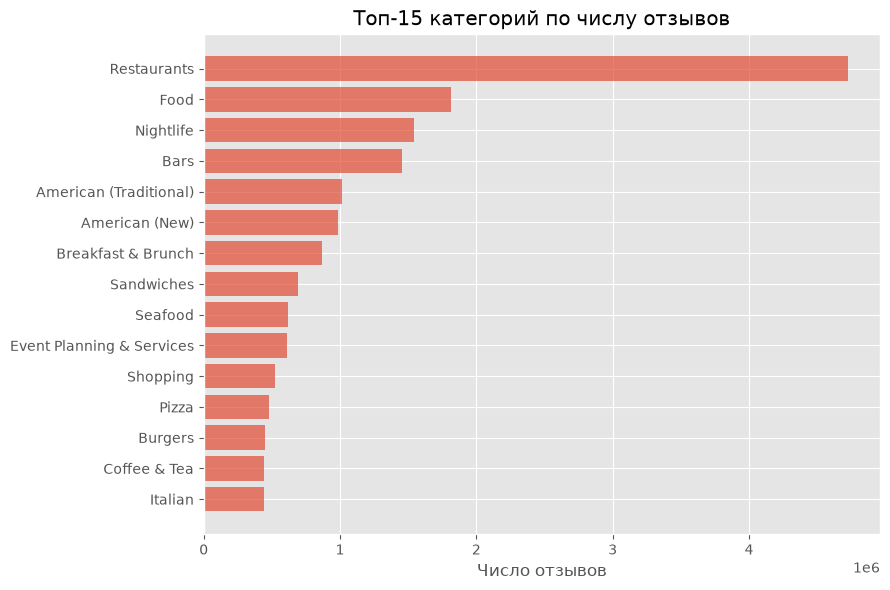

In [217]:
business_review_counts = reviews.group_by("business_id").agg(pl.len().alias("n_reviews"))

category_counts = (
    business_data
    .select(
        "business_id",
        pl.col("categories").str.split(",").list.eval(pl.element().str.strip_chars()).alias("category"),
    )
    .explode("category")
    .filter(pl.col("category").is_not_null())
    .join(business_review_counts, on="business_id", how="left")
    .group_by("category")
    .agg(
        pl.len().alias("n_business"),
        pl.col("n_reviews").sum().alias("n_reviews"),
    )
    .sort("n_reviews", descending=True)
)
print(f"Уникальных категорий: {category_counts.height:,}")

top15 = category_counts.head(15)
print(top15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15["category"].to_list()[::-1], top15["n_reviews"].to_list()[::-1], alpha=0.7)
ax.set_xlabel("Число отзывов")
ax.set_title("Топ-15 категорий по числу отзывов")
plt.tight_layout()
plt.show()

### Динамика во времени

Для выбора границ train, validation и test важно понимать, как меняется объём данных
по периодам (рост сервиса, сезонность, резкие спады активности). Динамика средней оценки 
показывает, меняются ли предпочтения пользователей со временем

shape: (18, 3)
┌──────┬───────────┬────────────┐
│ year ┆ n_reviews ┆ mean_stars │
│ ---  ┆ ---       ┆ ---        │
│ i32  ┆ u32       ┆ f64        │
╞══════╪═══════════╪════════════╡
│ 2005 ┆ 854       ┆ 3.9        │
│ 2006 ┆ 3853      ┆ 3.995      │
│ 2007 ┆ 15363     ┆ 3.864      │
│ 2008 ┆ 48226     ┆ 3.799      │
│ 2009 ┆ 74387     ┆ 3.719      │
│ 2010 ┆ 138587    ┆ 3.721      │
│ 2011 ┆ 230813    ┆ 3.705      │
│ 2012 ┆ 286570    ┆ 3.679      │
│ 2013 ┆ 383950    ┆ 3.684      │
│ 2014 ┆ 522275    ┆ 3.723      │
│ 2015 ┆ 688415    ┆ 3.742      │
│ 2016 ┆ 758882    ┆ 3.766      │
│ 2017 ┆ 820048    ┆ 3.779      │
│ 2018 ┆ 906362    ┆ 3.781      │
│ 2019 ┆ 907284    ┆ 3.767      │
│ 2020 ┆ 554557    ┆ 3.783      │
│ 2021 ┆ 618189    ┆ 3.705      │
│ 2022 ┆ 31665     ┆ 3.705      │
└──────┴───────────┴────────────┘


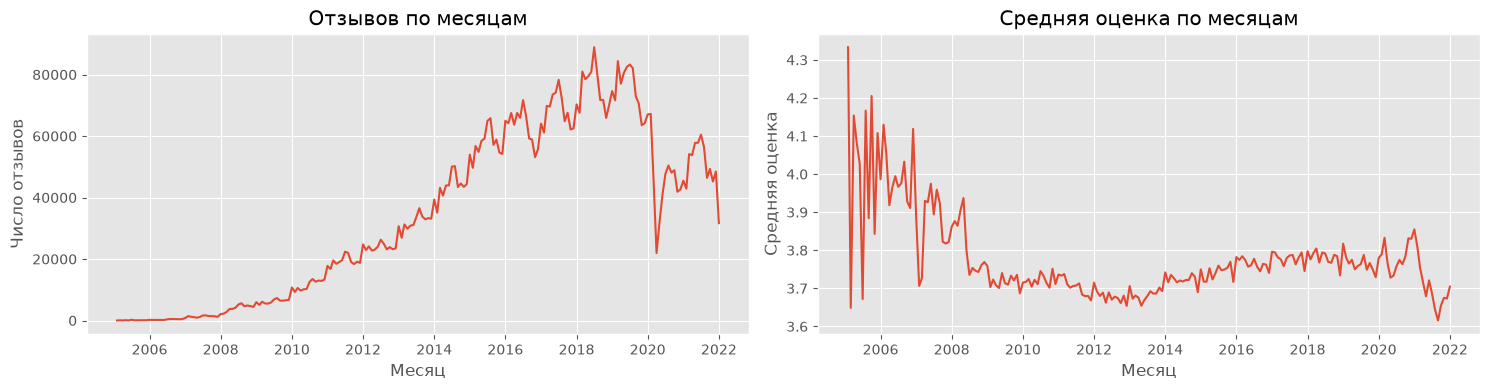

In [218]:
yearly = (
    reviews.group_by(pl.col("date").dt.year().alias("year"))
    .agg(
        pl.len().alias("n_reviews"),
        pl.col("stars").mean().round(3).alias("mean_stars"),
    )
    .sort("year")
)
monthly = (
    reviews.group_by(pl.col("date").dt.truncate("1mo").alias("month"))
    .agg(
        pl.len().alias("n_reviews"),
        pl.col("stars").mean().alias("mean_stars"),
    )
    .sort("month")
)
print(yearly)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(monthly["month"].to_numpy(), monthly["n_reviews"].to_numpy())
axes[0].set_xlabel("Месяц")
axes[0].set_ylabel("Число отзывов")
axes[0].set_title("Отзывов по месяцам")

axes[1].plot(monthly["month"].to_numpy(), monthly["mean_stars"].to_numpy())
axes[1].set_xlabel("Месяц")
axes[1].set_ylabel("Средняя оценка")
axes[1].set_title("Средняя оценка по месяцам")

plt.tight_layout()
plt.show()

### Дополнительные сигналы

Голоса «полезно», «смешно», «круто» за отзывы, советы (tip)
и чекины. Их частота и пересечение с отзывами показывают, насколько эти сигналы информативны
и можно ли использовать их для признаков

=== Голоса за отзывы ===
useful   - доля отзывов с голосами: 45.06%, среднее число голосов: 1.185
funny    - доля отзывов с голосами: 15.68%, среднее число голосов: 0.327
cool     - доля отзывов с голосами: 23.07%, среднее число голосов: 0.499

=== Советы (tip) ===
Советов:                    908,915
Пользователей:              301,758
Заведений:                  106,193
Доля пар (user, business) из советов, для которых есть отзыв: 0.3770

=== Чекины ===
Заведений с чекинами:       131,930
Всего чекинов:              13,356,875
Медиана чекинов на заведение: 20


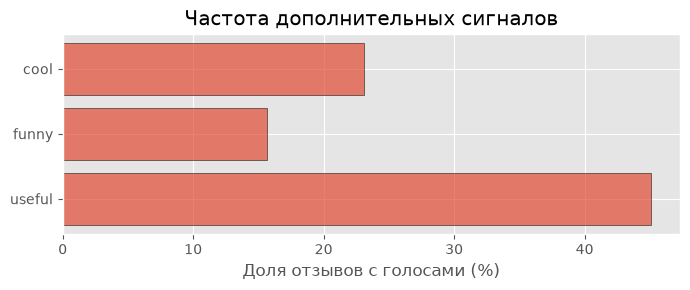

In [219]:
signals = ["useful", "funny", "cool"]
signal_rates = [(reviews[col] > 0).mean() * 100 for col in signals]

print("=== Голоса за отзывы ===")
for col, rate in zip(signals, signal_rates):
    print(f"{col:8s} - доля отзывов с голосами: {rate:.2f}%, среднее число голосов: {reviews[col].mean():.3f}")

tip_pairs = tip_data.select("user_id", "business_id").unique()
review_pairs = reviews.select("user_id", "business_id").unique()
tip_overlap = tip_pairs.join(review_pairs, on=["user_id", "business_id"], how="semi").height

print("\n=== Советы (tip) ===")
print(f"Советов:                    {tip_data.height:,}")
print(f"Пользователей:              {tip_data['user_id'].n_unique():,}")
print(f"Заведений:                  {tip_data['business_id'].n_unique():,}")
print(f"Доля пар (user, business) из советов, для которых есть отзыв: {tip_overlap / tip_pairs.height:.4f}")

checkins_per_business = checkin_data.select(pl.col("date").str.split(",").list.len().alias("n"))["n"]

print("\n=== Чекины ===")
print(f"Заведений с чекинами:       {checkin_data.height:,}")
print(f"Всего чекинов:              {checkins_per_business.sum():,}")
print(f"Медиана чекинов на заведение: {checkins_per_business.median():.0f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(signals, signal_rates, edgecolor="black", alpha=0.7)
ax.set_xlabel("Доля отзывов с голосами (%)")
ax.set_title("Частота дополнительных сигналов")
plt.tight_layout()
plt.show()

### Пропуски

Oтсутствие значения кодируется: `null`, пустой строкой и строковым значением `"None"`

Пустая строка в `elite` означает, что пользователь никогда не имел статуса Elite, а `"None"` в `friends` - что у пользователя
нет друзей

In [220]:
def missing_report(df: pl.DataFrame, table: str) -> pl.DataFrame:
    """Число null, пустых строк и строк 'None' по каждому столбцу таблицы."""
    rows = []
    for col, dtype in df.schema.items():
        n_null = df[col].null_count()
        n_empty = 0
        if dtype == pl.String:
            n_empty = df.select(pl.col(col).is_in(["", "None"]).sum()).item()
        rows.append({
            "table": table,
            "column": col,
            "dtype": str(dtype)[:30],
            "null": n_null,
            "empty_or_None": n_empty,
            "missing_share": round((n_null + n_empty) / df.height, 4),
        })
    return pl.DataFrame(rows)


tables = {
    "business": business_data,
    "review": review_data,
    "user": user_data,
    "tip": tip_data,
    "checkin": checkin_data,
}
missing = pl.concat([missing_report(df, name) for name, df in tables.items()])

with pl.Config(tbl_rows=-1, fmt_str_lengths=40):
    print(missing.sort("missing_share", descending=True))
print(f"\nСтолбцов без пропусков: {missing.filter(pl.col('missing_share') == 0).height} из {missing.height}")

shape: (52, 6)
┌──────────┬────────────────────┬──────────────────────────┬───────┬───────────────┬───────────────┐
│ table    ┆ column             ┆ dtype                    ┆ null  ┆ empty_or_None ┆ missing_share │
│ ---      ┆ ---                ┆ ---                      ┆ ---   ┆ ---           ┆ ---           │
│ str      ┆ str                ┆ str                      ┆ i64   ┆ i64           ┆ f64           │
╞══════════╪════════════════════╪══════════════════════════╪═══════╪═══════════════╪═══════════════╡
│ user     ┆ elite              ┆ String                   ┆ 0     ┆ 1896699       ┆ 0.9541        │
│ user     ┆ friends            ┆ String                   ┆ 0     ┆ 878551        ┆ 0.4419        │
│ business ┆ hours              ┆ Struct({'Monday':        ┆ 23223 ┆ 0             ┆ 0.1545        │
│          ┆                    ┆ String, 'Tue             ┆       ┆               ┆               │
│ business ┆ attributes         ┆ Struct({'BusinessParking ┆ 13744 ┆ 0      

In [221]:
marker_rows = []
for name, df in tables.items():
    for col, dtype in df.schema.items():
        if dtype != pl.String:
            continue
        n_empty = df.select((pl.col(col) == "").sum()).item()
        n_none = df.select((pl.col(col) == "None").sum()).item()
        if n_empty or n_none:
            marker_rows.append({"table": name, "column": col, "empty_string": n_empty, "string_None": n_none})
print(pl.DataFrame(marker_rows))

print("\nПримеры непустых значений elite:")
print(user_data.filter(pl.col("elite") != "")["elite"].head(5).to_list())

print("\nПримеры значений friends, отличных от 'None' (первые 100 символов):")
print(user_data.filter(pl.col("friends") != "None")["friends"].head(2).str.slice(0, 100).to_list())

first_friend_len = (
    user_data.filter(pl.col("friends") != "None")
    .select(pl.col("friends").str.split(",").list.first().str.strip_chars().str.len_chars().alias("length"))
    .group_by("length").agg(pl.len().alias("n_users"))
    .sort("n_users", descending=True)
)
print("\nДлина первого идентификатора в friends:")
print(first_friend_len.head(5))
print("Длины user_id:", user_data["user_id"].str.len_chars().unique().to_list())

shape: (6, 4)
┌──────────┬─────────────┬──────────────┬─────────────┐
│ table    ┆ column      ┆ empty_string ┆ string_None │
│ ---      ┆ ---         ┆ ---          ┆ ---         │
│ str      ┆ str         ┆ i64          ┆ i64         │
╞══════════╪═════════════╪══════════════╪═════════════╡
│ business ┆ address     ┆ 5127         ┆ 0           │
│ business ┆ postal_code ┆ 73           ┆ 0           │
│ user     ┆ name        ┆ 0            ┆ 29          │
│ user     ┆ elite       ┆ 1896699      ┆ 0           │
│ user     ┆ friends     ┆ 0            ┆ 878551      │
│ tip      ┆ text        ┆ 0            ┆ 9           │
└──────────┴─────────────┴──────────────┴─────────────┘

Примеры непустых значений elite:
['2007', '2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021', '2009,2010,2011,2012,2013', '2009,2010,2011', '2006,2007,2008,2009,2010,2011,2012,2013,2014']

Примеры значений friends, отличных от 'None' (первые 100 символов):
['NSCy54eWehBJyZdG2iE84w, pe42u7DcCH2Qm

#### Заполненность атрибутов заведений

Поле `attributes` - структура, каждое поле которой (ценовой уровень, Wi-Fi, парковка и т. д.)
является отдельным потенциальным признаком для FM. Заполненность оценивается
по каждому атрибуту отдельно

In [222]:
attrs = business_data.select("business_id", "attributes").unnest("attributes")
attr_cols = [c for c in attrs.columns if c != "business_id"]

attr_fill = pl.DataFrame({
    "attribute": attr_cols,
    "filled_share": [
        attrs.select(
            (pl.col(c).is_not_null() & (pl.col(c).cast(pl.String) != "None")).mean()
        ).item()
        for c in attr_cols
    ],
}).sort("filled_share", descending=True)

n_no_attrs = business_data["attributes"].null_count()
print(f"Атрибутов в структуре: {len(attr_cols)}")
print(f"Заведений без атрибутов: {n_no_attrs:,} ({n_no_attrs / business_data.height:.2%})")
with pl.Config(tbl_rows=-1):
    print(attr_fill)

Атрибутов в структуре: 39
Заведений без атрибутов: 13,744 (9.14%)
shape: (39, 2)
┌────────────────────────────┬──────────────┐
│ attribute                  ┆ filled_share │
│ ---                        ┆ ---          │
│ str                        ┆ f64          │
╞════════════════════════════╪══════════════╡
│ BusinessAcceptsCreditCards ┆ 0.79611      │
│ BusinessParking            ┆ 0.590731     │
│ RestaurantsPriceRange2     ┆ 0.567225     │
│ BikeParking                ┆ 0.482607     │
│ RestaurantsTakeOut         ┆ 0.384127     │
│ WiFi                       ┆ 0.378221     │
│ GoodForKids                ┆ 0.354828     │
│ RestaurantsDelivery        ┆ 0.34809      │
│ OutdoorSeating             ┆ 0.31208      │
│ HasTV                      ┆ 0.299742     │
│ RestaurantsReservations    ┆ 0.299037     │
│ RestaurantsGoodForGroups   ┆ 0.293649     │
│ Ambience                   ┆ 0.290849     │
│ Alcohol                    ┆ 0.287011     │
│ ByAppointmentOnly          ┆ 0.281344     │

### Дубликаты

Одна и та же пара может попасть в train и test, матрица user x item искажается. Проверяются уникальность идентификаторов во всех таблицах,
полные дубликаты отзывов и советов, а также повторные отзывы одной пары (пользователь, заведение).

In [223]:
pair_stats = (
    reviews.group_by(["user_id", "business_id"])
    .agg(
        pl.len().alias("n_reviews"),
        pl.col("stars").n_unique().alias("n_distinct_stars"),
        (pl.col("date").max() - pl.col("date").min()).dt.total_days().alias("days_between"),
    )
)
multi_pairs = pair_stats.filter(pl.col("n_reviews") > 1)

review_key = ["user_id", "business_id", "stars", "date"]
tip_key = ["user_id", "business_id", "date"]

duplicates = {
    "повторы business_id в business": business_data.height - business_data["business_id"].n_unique(),
    "повторы user_id в user": user_data.height - user_data["user_id"].n_unique(),
    "повторы business_id в checkin": checkin_data.height - checkin_data["business_id"].n_unique(),
    "повторы review_id в review": review_data.height - review_data["review_id"].n_unique(),
    "лишние копии отзывов (user, business, stars, date)": reviews.height - reviews.select(review_key).unique().height,
    "лишние копии советов (user, business, date)": tip_data.height - tip_data.select(tip_key).unique().height,
    "пар (user, business) с несколькими отзывами": multi_pairs.height,
    "отзывов в таких парах": int(multi_pairs["n_reviews"].sum()),
    "пар с различающимися оценками": multi_pairs.filter(pl.col("n_distinct_stars") > 1).height,
}
with pl.Config(fmt_str_lengths=80):
    print(pl.DataFrame({"check": list(duplicates), "value": list(duplicates.values())}))

if multi_pairs.height > 0:
    print(f"\nДоля пар с повторными отзывами: {multi_pairs.height / pair_stats.height:.4f}")
    print(f"Медианный интервал между первым и последним отзывом пары: "
          f"{multi_pairs['days_between'].median():.0f} дней")

shape: (9, 2)
┌────────────────────────────────────────────────────┬────────┐
│ check                                              ┆ value  │
│ ---                                                ┆ ---    │
│ str                                                ┆ i64    │
╞════════════════════════════════════════════════════╪════════╡
│ повторы business_id в business                     ┆ 0      │
│ повторы user_id в user                             ┆ 0      │
│ повторы business_id в checkin                      ┆ 0      │
│ повторы review_id в review                         ┆ 0      │
│ лишние копии отзывов (user, business, stars, date) ┆ 25     │
│ лишние копии советов (user, business, date)        ┆ 79     │
│ пар (user, business) с несколькими отзывами        ┆ 212788 │
│ отзывов в таких парах                              ┆ 457308 │
│ пар с различающимися оценками                      ┆ 93993  │
└────────────────────────────────────────────────────┴────────┘

Доля пар с повторными отз

### Анализ метаданных

Метаданные нужны для FM. Для каждого признака важно понять его заполненность,
число различных значений и распределение, а также то, **известен ли он в момент рекомендации**.
Признак, вычисленный с использованием будущих взаимодействий, создаёт утечку

#### География

Пользователь обычно выбирает заведение в своём городе. Распределение отзывов по географии показывает, насколько это правда.
Если большинство отзывов пользователя в одном регионе, то логично подвыборку строить по региону - кандидаты остаются географически достижимыми, а город можно использовать как признак

Штатов: 27, городов: 1,416
shape: (15, 4)
┌───────┬────────────┬───────────┬─────────┐
│ state ┆ n_business ┆ n_reviews ┆ n_users │
│ ---   ┆ ---        ┆ ---       ┆ ---     │
│ str   ┆ u32        ┆ u32       ┆ u32     │
╞═══════╪════════════╪═══════════╪═════════╡
│ PA    ┆ 34039      ┆ 1598960   ┆ 430688  │
│ FL    ┆ 26330      ┆ 1161545   ┆ 348697  │
│ LA    ┆ 9924       ┆ 761673    ┆ 273391  │
│ TN    ┆ 12056      ┆ 614388    ┆ 222122  │
│ MO    ┆ 10913      ┆ 502385    ┆ 151620  │
│ IN    ┆ 11247      ┆ 489752    ┆ 129736  │
│ AZ    ┆ 9912       ┆ 431708    ┆ 126306  │
│ NV    ┆ 7715       ┆ 430678    ┆ 134285  │
│ CA    ┆ 5203       ┆ 348856    ┆ 155949  │
│ NJ    ┆ 8536       ┆ 260897    ┆ 100438  │
│ ID    ┆ 4467       ┆ 157572    ┆ 56962   │
│ AB    ┆ 5573       ┆ 109436    ┆ 23793   │
│ DE    ┆ 2265       ┆ 70302     ┆ 32535   │
│ IL    ┆ 2145       ┆ 51832     ┆ 22248   │
│ MA    ┆ 2          ┆ 44        ┆ 43      │
└───────┴────────────┴───────────┴─────────┘

Доля пользов

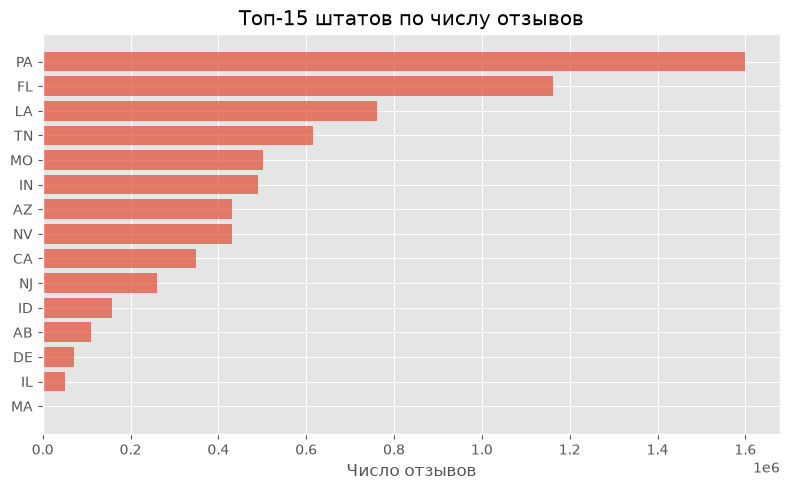

In [224]:
reviews_geo = reviews.join(business_data.select("business_id", "state", "city"), on="business_id")

state_stats = (
    business_data.group_by("state").agg(pl.len().alias("n_business"))
    .join(
        reviews_geo.group_by("state").agg(
            pl.len().alias("n_reviews"),
            pl.col("user_id").n_unique().alias("n_users"),
        ),
        on="state",
        how="left",
    )
    .sort("n_reviews", descending=True, nulls_last=True)
)
print(f"Штатов: {business_data['state'].n_unique()}, городов: {business_data['city'].n_unique():,}")
print(state_stats.head(15))

user_states = (
    reviews_geo.group_by(["user_id", "state"]).agg(pl.len().alias("n"))
    .group_by("user_id")
    .agg(
        pl.col("n").max().alias("n_main_state"),
        pl.col("n").sum().alias("n_total"),
        pl.len().alias("n_states"),
    )
)
print(f"\nДоля пользователей с отзывами более чем в одном штате: "
      f"{(user_states['n_states'] > 1).mean():.4f}")
print(f"Доля отзывов, приходящихся на основной штат пользователя: "
      f"{user_states['n_main_state'].sum() / user_states['n_total'].sum():.4f}")

top_states = state_stats.head(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_states["state"].to_list()[::-1], top_states["n_reviews"].to_list()[::-1], alpha=0.7)
ax.set_xlabel("Число отзывов")
ax.set_title("Топ-15 штатов по числу отзывов")
plt.tight_layout()
plt.show()

In [225]:
# Та же проверка на уровне городов
user_cities = (
    reviews_geo.group_by(["user_id", "state", "city"]).agg(pl.len().alias("n"))
    .group_by("user_id")
    .agg(
        pl.col("n").max().alias("n_main_city"),
        pl.col("n").sum().alias("n_total"),
        pl.len().alias("n_cities"),
    )
)
print(f"Доля пользователей с отзывами более чем в одном городе: {(user_cities['n_cities'] > 1).mean():.4f}")
print(f"Доля отзывов, приходящихся на основной город пользователя: "
      f"{user_cities['n_main_city'].sum() / user_cities['n_total'].sum():.4f}")

n_city_raw = business_data["city"].n_unique()
n_city_norm = business_data.select(pl.col("city").str.strip_chars().str.to_lowercase()).n_unique()
print(f"Различных названий городов: {n_city_raw:,}; после приведения к нижнему регистру: {n_city_norm:,}")

Доля пользователей с отзывами более чем в одном городе: 0.2651
Доля отзывов, приходящихся на основной город пользователя: 0.7246
Различных названий городов: 1,416; после приведения к нижнему регистру: 1,238


#### Категории заведений как признак

Одно заведение относится к нескольким категориям.
Для FM это означает несколько ненулевых элементов в векторе признаков на одно заведение. Число
категорий на заведение и доля редких категорий показывают, насколько разреженным будет этот блок
признаков и есть ли смысл объединять редкие категории.

Категорий на заведение:
Mean:    4.450070885166031
Median:  4.0
Max:     36

Уникальных категорий: 1,311
Доля категорий, встречающихся менее чем у  10 заведений: 0.1800
Доля категорий, встречающихся менее чем у  50 заведений: 0.4523
Доля категорий, встречающихся менее чем у 100 заведений: 0.5706


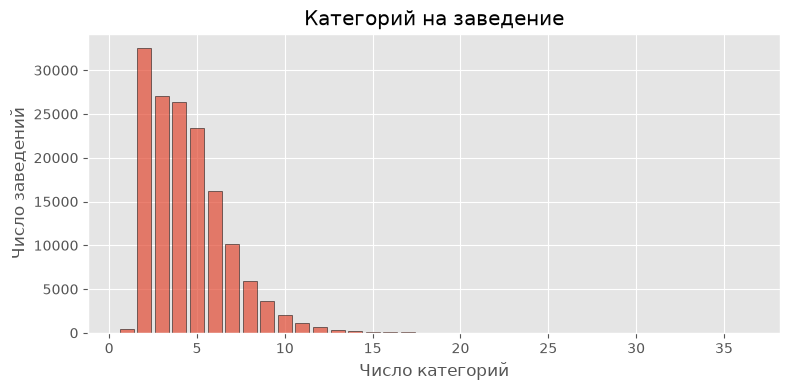

In [226]:
categories_per_business = business_data.select(
    pl.col("categories").str.split(",").list.len().alias("n_categories")
)["n_categories"].drop_nulls()

print("Категорий на заведение:")
print("Mean:   ", categories_per_business.mean())
print("Median: ", categories_per_business.median())
print("Max:    ", categories_per_business.max())
print()
print(f"Уникальных категорий: {category_counts.height:,}")
for t in [10, 50, 100]:
    share = (category_counts["n_business"] < t).mean()
    print(f"Доля категорий, встречающихся менее чем у {t:>3} заведений: {share:.4f}")

counts = categories_per_business.value_counts().sort(categories_per_business.name)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts[categories_per_business.name].to_numpy(), counts[counts.columns[1]].to_numpy(),
       edgecolor="black", alpha=0.7)
ax.set_xlabel("Число категорий")
ax.set_ylabel("Число заведений")
ax.set_title("Категорий на заведение")
plt.tight_layout()
plt.show()

#### Атрибуты заведений

Рассматриваются атрибуты, которые могут описывать
заведение для FM: ценовой уровень, уровень шума, наличие алкоголя, Wi-Fi, дресс-код и летняя
веранда. Распределение значений показывает, насколько признак различает заведения.

In [227]:
# Исходные значения атрибутов до очистки
raw_rows = []
for col in attr_cols:
    raw = attrs[col].cast(pl.String).drop_nulls()
    raw_rows.append({
        "attribute": col,
        "non_null_share": round(raw.len() / attrs.height, 4),
        "n_raw_values": raw.n_unique(),
        "raw_examples": " | ".join(raw.unique().sort().head(5).to_list()),
    })
with pl.Config(tbl_rows=-1, fmt_str_lengths=90):
    print(pl.DataFrame(raw_rows).sort("non_null_share", descending=True))

shape: (39, 4)
┌────────────────────────────┬────────────────┬──────────────┬─────────────────────────────────────┐
│ attribute                  ┆ non_null_share ┆ n_raw_values ┆ raw_examples                        │
│ ---                        ┆ ---            ┆ ---          ┆ ---                                 │
│ str                        ┆ f64            ┆ i64          ┆ str                                 │
╞════════════════════════════╪════════════════╪══════════════╪═════════════════════════════════════╡
│ BusinessAcceptsCreditCards ┆ 0.7966         ┆ 3            ┆ False | None | True                 │
│ BusinessParking            ┆ 0.6058         ┆ 165          ┆ None | {'garage': False, 'street':  │
│                            ┆                ┆              ┆ False, 'validated': False, 'lot':   │
│                            ┆                ┆              ┆ False, 'valet': False…              │
│ RestaurantsPriceRange2     ┆ 0.5675         ┆ 5            ┆ 1 | 2 | 3 | 4

shape: (5, 2)
┌────────────────────────┬────────────┐
│ RestaurantsPriceRange2 ┆ n_business │
│ ---                    ┆ ---        │
│ str                    ┆ u32        │
╞════════════════════════╪════════════╡
│ null                   ┆ 65066      │
│ 2                      ┆ 48581      │
│ 1                      ┆ 28840      │
│ 3                      ┆ 6667       │
│ 4                      ┆ 1192       │
└────────────────────────┴────────────┘
shape: (5, 2)
┌────────────┬────────────┐
│ NoiseLevel ┆ n_business │
│ ---        ┆ ---        │
│ str        ┆ u32        │
╞════════════╪════════════╡
│ null       ┆ 112392     │
│ average    ┆ 26188      │
│ quiet      ┆ 7634       │
│ loud       ┆ 2932       │
│ very_loud  ┆ 1200       │
└────────────┴────────────┘
shape: (4, 2)
┌───────────────┬────────────┐
│ Alcohol       ┆ n_business │
│ ---           ┆ ---        │
│ str           ┆ u32        │
╞═══════════════╪════════════╡
│ null          ┆ 107195     │
│ none          ┆ 20910 

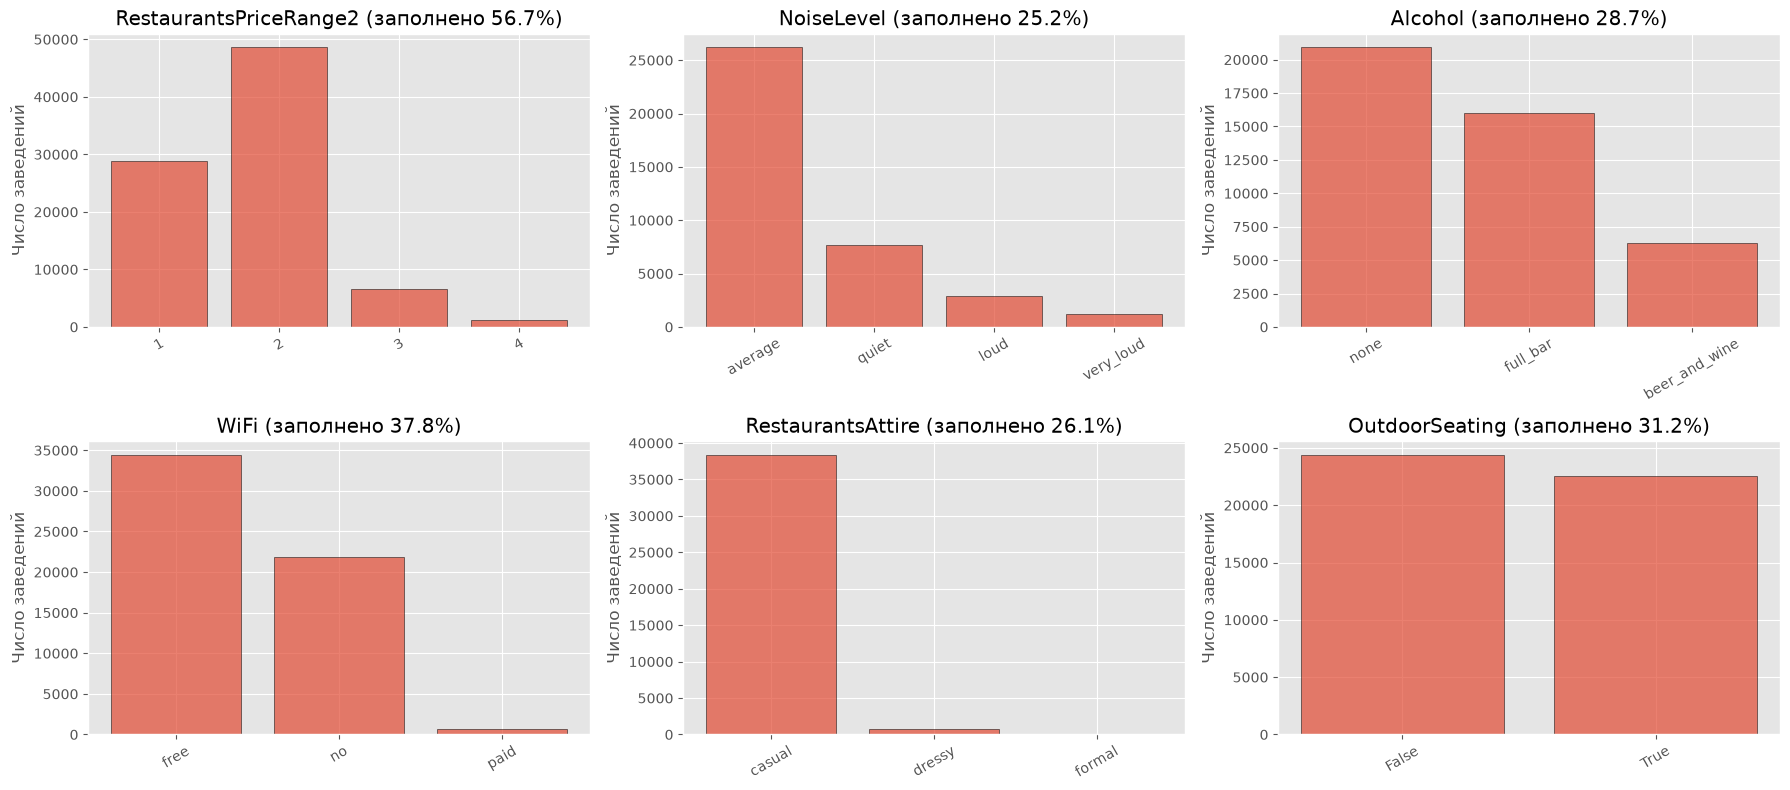

In [228]:
def clean_attr(col: str) -> pl.Expr:
    """u'free' / 'free' / 'None' -> free / null."""
    return (
        pl.col(col).cast(pl.String)
        .str.replace_all(r"^u?'|'$", "")
        .replace("None", None)
        .alias(col)
    )


ATTRS_TO_SHOW = ["RestaurantsPriceRange2", "NoiseLevel", "Alcohol", "WiFi", "RestaurantsAttire", "OutdoorSeating"]

cols = [c for c in ATTRS_TO_SHOW if c in attrs.columns]

for col in cols:
    values = (
        attrs.select(clean_attr(col))
        .group_by(col).agg(pl.len().alias("n_business"))
        .sort("n_business", descending=True)
    )
    print(values)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.flat, cols):
    rows = (
        attrs.select(clean_attr(col)).drop_nulls()
        .group_by(col).agg(pl.len().alias("n_business"))
        .sort("n_business", descending=True)
        .rows()
    )
    if all(r[0].isdigit() for r in rows):
        rows.sort(key=lambda r: int(r[0]))
    filled = attrs.select(clean_attr(col).is_not_null().mean()).item()

    ax.bar([r[0] for r in rows], [r[1] for r in rows], edgecolor="black", alpha=0.7)
    ax.set_title(f"{col} (заполнено {filled:.1%})")
    ax.set_ylabel("Число заведений")
    ax.tick_params(axis="x", rotation=30)

for ax in list(axes.flat)[len(cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Агрегаты по заведениям

shape: (2, 4)
┌─────────┬────────────┬─────────────────────────┬────────────────┐
│ is_open ┆ n_business ┆ median_last_review      ┆ median_reviews │
│ ---     ┆ ---        ┆ ---                     ┆ ---            │
│ i64     ┆ u32        ┆ datetime[μs]            ┆ f64            │
╞═════════╪════════════╪═════════════════════════╪════════════════╡
│ 0       ┆ 30648      ┆ 2017-09-01 16:46:04.500 ┆ 15.0           │
│ 1       ┆ 119698     ┆ 2021-08-25 18:32:31.500 ┆ 15.0           │
└─────────┴────────────┴─────────────────────────┴────────────────┘


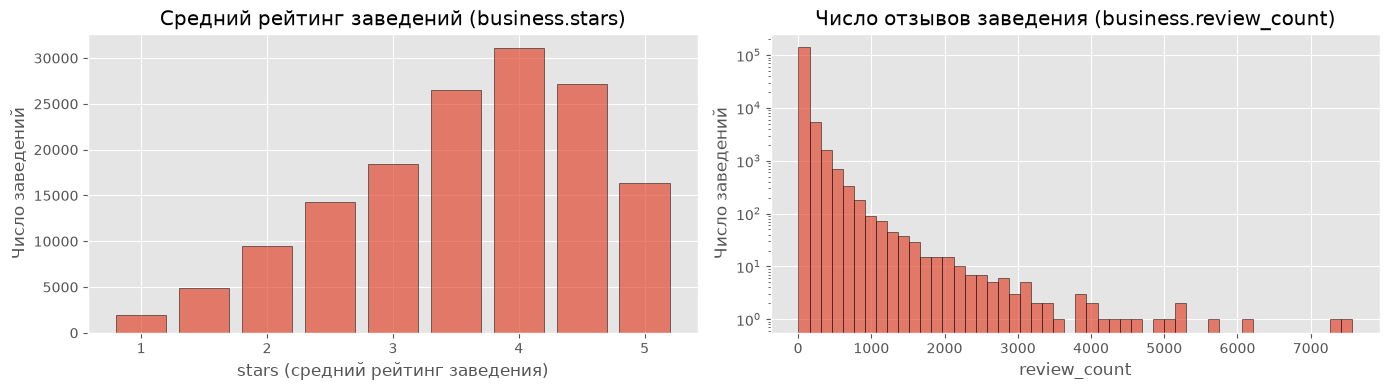

In [229]:
business_activity = reviews.group_by("business_id").agg(
    pl.len().alias("actual_reviews"),
    pl.col("stars").mean().alias("actual_mean_stars"),
    pl.col("date").max().alias("last_review"),
)
business_cmp = business_data.select("business_id", "stars", "review_count", "is_open").join(
    business_activity, on="business_id", how="inner"
)

print(
    business_cmp.group_by("is_open")
    .agg(
        pl.len().alias("n_business"),
        pl.col("last_review").median().alias("median_last_review"),
        pl.col("actual_reviews").median().alias("median_reviews"),
    )
    .sort("is_open")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
star_values = business_data.group_by("stars").agg(pl.len().alias("n")).sort("stars")
axes[0].bar(star_values["stars"].to_numpy(), star_values["n"].to_numpy(), width=0.4, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("stars (средний рейтинг заведения)")
axes[0].set_ylabel("Число заведений")
axes[0].set_title("Средний рейтинг заведений (business.stars)")

axes[1].hist(business_data["review_count"].to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[1].set_yscale("log")
axes[1].set_xlabel("review_count")
axes[1].set_ylabel("Число заведений")
axes[1].set_title("Число отзывов заведения (business.review_count)")
plt.tight_layout()
plt.show()

#### Регистрация пользователей

`yelping_since` - дата регистрации пользователя, если поле - дата регистрации, отзывы пользователя не должны быть оставлены
раньше неё. Если условие выполняется практически для всех отзывов, возраст аккаунта можно использовать как признак.

In [230]:
# Формат исходных строк yelping_since в user.json
ys_lengths = (
    user_data.select(pl.col("yelping_since").str.len_chars().alias("length"))
    .group_by("length").agg(pl.len().alias("n_users"))
    .sort("length")
)
print(ys_lengths)
print("Примеры исходных строк yelping_since:", user_data["yelping_since"].head(3).to_list())

shape: (1, 2)
┌────────┬─────────┐
│ length ┆ n_users │
│ ---    ┆ ---     │
│ u32    ┆ u32     │
╞════════╪═════════╡
│ 19     ┆ 1987897 │
└────────┴─────────┘
Примеры исходных строк yelping_since: ['2007-01-25 16:47:26', '2009-01-25 04:35:42', '2008-07-25 10:41:00']


Нераспознанных дат регистрации: 0
Отзывов, оставленных раньше регистрации автора: 115
Возраст аккаунта на момент отзыва, лет: медиана 2.66


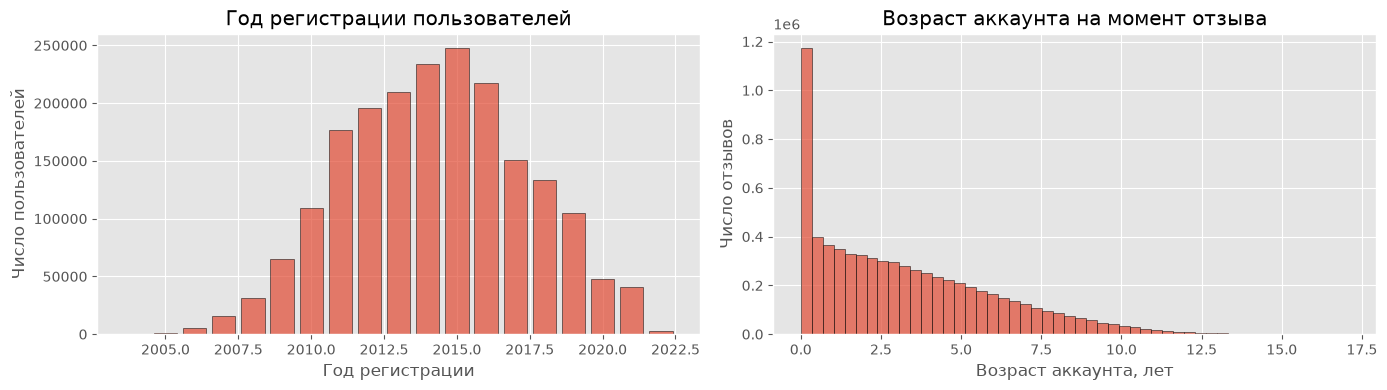

In [231]:
ys = pl.col("yelping_since")
users_meta = user_data.select(
    "user_id",
    pl.coalesce(
        ys.str.to_datetime("%Y-%m-%d %H:%M:%S", strict=False),
        ys.str.to_datetime("%Y-%m-%d", strict=False),
    ).alias("yelping_since"),
    "review_count",
    "average_stars",
    "fans",
    "elite",
    pl.when(pl.col("friends").is_in(["None", ""]) | pl.col("friends").is_null())
      .then(0)
      .otherwise(pl.col("friends").str.count_matches(",") + 1)
      .alias("n_friends"),
)

account_age = (
    reviews.select("user_id", "date")
    .join(users_meta.select("user_id", "yelping_since"), on="user_id", how="inner")
    .select(((pl.col("date") - pl.col("yelping_since")).dt.total_days() / 365.25).alias("age_years"))
)["age_years"]

print(f"Нераспознанных дат регистрации: {users_meta['yelping_since'].null_count():,}")
print(f"Отзывов, оставленных раньше регистрации автора: {(account_age < 0).sum():,}")
print(f"Возраст аккаунта на момент отзыва, лет: медиана {account_age.median():.2f}")

signup = (
    users_meta.group_by(pl.col("yelping_since").dt.year().alias("year"))
    .agg(pl.len().alias("n_users")).drop_nulls().sort("year")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(signup["year"].to_numpy(), signup["n_users"].to_numpy(), edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Год регистрации")
axes[0].set_ylabel("Число пользователей")
axes[0].set_title("Год регистрации пользователей")

axes[1].hist(account_age.filter(account_age >= 0).to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Возраст аккаунта, лет")
axes[1].set_ylabel("Число отзывов")
axes[1].set_title("Возраст аккаунта на момент отзыва")
plt.tight_layout()
plt.show()

#### Статус Elite, друзья и подписчики

In [232]:
elite_long = (
    user_data.select("user_id", pl.col("elite").str.split(",").alias("token"))
    .explode("token")
    .with_columns(pl.col("token").str.strip_chars())
    .filter(pl.col("token").is_not_null() & (pl.col("token") != ""))
)
token_counts = elite_long.group_by("token").agg(pl.len().alias("n")).sort("token")
with pl.Config(tbl_rows=-1):
    print(token_counts)

# Проверка гипотезы «'20,20' - это 2020 год»
n_users_2020 = elite_long.filter(pl.col("token") == "2020")["user_id"].n_unique()
twenty_per_user = elite_long.filter(pl.col("token") == "20").group_by("user_id").agg(pl.len().alias("n_20"))
print(f"Пользователей с элементом '2020': {n_users_2020:,}")
print(f"Пользователей с элементом '20':   {twenty_per_user.height:,}")
print(twenty_per_user.group_by("n_20").agg(pl.len().alias("n_users")).sort("n_20"))
print("Примеры строк elite с элементом '20':",
      user_data.filter(pl.col("elite").str.contains(r"(^|,)20(,|$)"))["elite"].head(3).to_list())

shape: (16, 2)
┌───────┬───────┐
│ token ┆ n     │
│ ---   ┆ ---   │
│ str   ┆ u32   │
╞═══════╪═══════╡
│ 20    ┆ 79858 │
│ 2006  ┆ 775   │
│ 2007  ┆ 2023  │
│ 2008  ┆ 3185  │
│ 2009  ┆ 5479  │
│ 2010  ┆ 8772  │
│ 2011  ┆ 10997 │
│ 2012  ┆ 15222 │
│ 2013  ┆ 16193 │
│ 2014  ┆ 18571 │
│ 2015  ┆ 24175 │
│ 2016  ┆ 29636 │
│ 2017  ┆ 36015 │
│ 2018  ┆ 41009 │
│ 2019  ┆ 44044 │
│ 2021  ┆ 44542 │
└───────┴───────┘
Пользователей с элементом '2020': 0
Пользователей с элементом '20':   39,929
shape: (1, 2)
┌──────┬─────────┐
│ n_20 ┆ n_users │
│ ---  ┆ ---     │
│ u32  ┆ u32     │
╞══════╪═════════╡
│ 2    ┆ 39929   │
└──────┴─────────┘
Примеры строк elite с элементом '20': ['2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021', '2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021', '2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,20,20,2021']


Гипотеза «пара '20,20' обозначает 2020 год» подтверждается данными: True

Доля пользователей, хотя бы раз имевших статус Elite: 0.0459
Доля пользователей без друзей: 0.4419
Доля пользователей без подписчиков: 0.7937


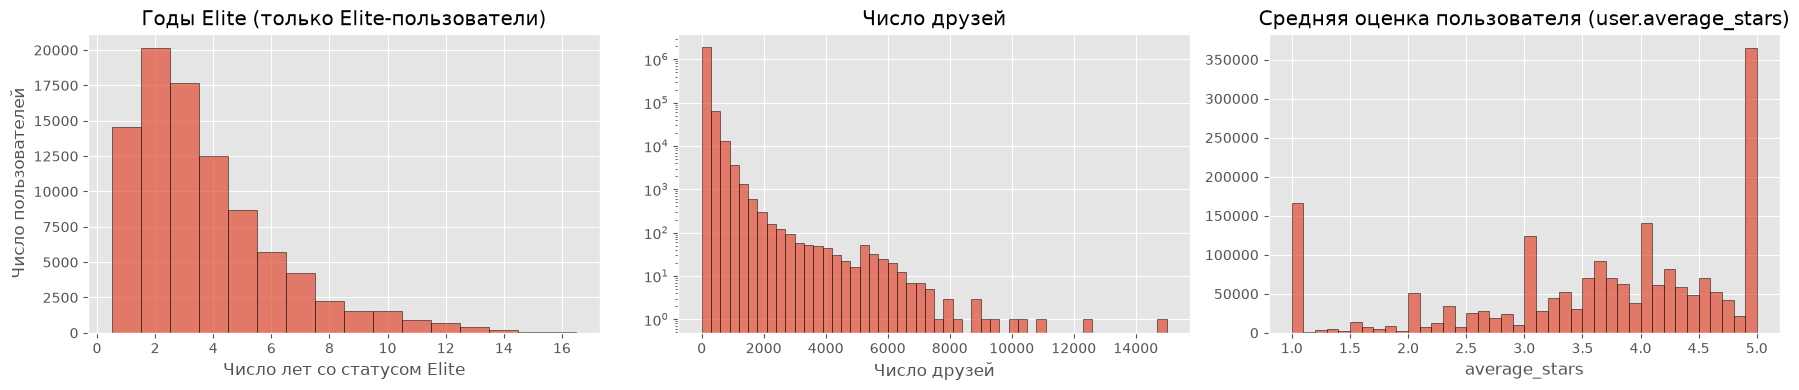

In [233]:
hypothesis_holds = (
    twenty_per_user.height > 0
    and n_users_2020 == 0
    and bool((twenty_per_user["n_20"] == 2).all())
)
print(f"Гипотеза «пара '20,20' обозначает 2020 год» подтверждается данными: {hypothesis_holds}")

# Число лет со статусом Elite: четырёхзначные элементы + (пары '20', если гипотеза подтверждена)
tokens = pl.col("elite").fill_null("").str.split(",").list.eval(pl.element().str.strip_chars())
n_four_digit = tokens.list.eval(pl.element().filter(pl.element().str.contains(r"^\d{4}$"))).list.len()
n_twenty = tokens.list.eval(pl.element().filter(pl.element() == "20")).list.len()
users_meta = users_meta.with_columns(
    ((n_four_digit + n_twenty // 2) if hypothesis_holds else n_four_digit).alias("n_elite_years")
)

elite_years = users_meta.filter(pl.col("n_elite_years") > 0)["n_elite_years"]
print(f"\nДоля пользователей, хотя бы раз имевших статус Elite: {(users_meta['n_elite_years'] > 0).mean():.4f}")
print(f"Доля пользователей без друзей: {(users_meta['n_friends'] == 0).mean():.4f}")
print(f"Доля пользователей без подписчиков: {(users_meta['fans'] == 0).mean():.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
if elite_years.len() > 0:
    axes[0].hist(elite_years.to_numpy(), bins=np.arange(0.5, elite_years.max() + 1.5, 1), edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Число лет со статусом Elite")
axes[0].set_ylabel("Число пользователей")
axes[0].set_title("Годы Elite (только Elite-пользователи)")

axes[1].hist(users_meta["n_friends"].to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[1].set_yscale("log")
axes[1].set_xlabel("Число друзей")
axes[1].set_title("Число друзей")

axes[2].hist(users_meta["average_stars"].to_numpy(), bins=40, edgecolor="black", alpha=0.7)
axes[2].set_xlabel("average_stars")
axes[2].set_title("Средняя оценка пользователя (user.average_stars)")
plt.tight_layout()
plt.show()

# Очистка, фильтрация и формирование подвыборки

1. **Очистка.** Удаляются отзывы с оценкой вне диапазона 1–5, с нераспознанной датой и отзывы о заведениях,
   отсутствующих в `business.json`. Для каждой пары (пользователь, заведение) остаётся последний по дате отзыв.
   *Почему:* в данных есть повторные отзывы одной пары, в том числе с разными оценками; матричным
   моделям нужно одно значение на ячейку, а при временном разбиении повторная пара могла бы попасть и в train,
   и в test.

2. **Пользователи без метаданных.** Удаляются отзывы пользователей, которых нет в `user.json`.
   *Почему:* для них нельзя построить пользовательские признаки FM (возраст аккаунта, годы Elite).

3. **Регион.** Выбирается штат с наибольшим числом отзывов.
   *Почему:* большая часть отзывов пользователя относится к одному штату, поэтому
   ограничение одним штатом мало сокращает историю пользователей, а кандидаты находятся в регионе пользователя.
   Самый крупный штат даёт наибольший объём данных.

4. **Категория `Restaurants`.** Остаются только заведения, в списке категорий которых есть `Restaurants`.
   *Почему:* это крупнейшая категория (52 268 заведений, 4 724 471 отзыв),
   а следующие за ней по числу отзывов категории в основном связаны с едой и заведениями питания. Если такие
   категории почти всегда встречаются вместе с `Restaurants`, их признаки в FM будут сильно зависимы.

5. **Обрезка периода.** Остаются только отзывы, оставленные до 01.01.2020.
   *Почему:* количество отзывов с 2020 года резко упало, это приведёт к заниженной и плохо сопоставимой с val оценке на test.

6. **Пороги отсева.** Для пользователей и для заведений вычисляются статистики числа отзывов: среднее, медиана и 15-й процентиль. 
   Процентиль берётся как ближайшее наблюдаемое значение (`interpolation="nearest"`).
   Пользователь или заведение отсеивается, если число его отзывов **меньше** порога.
   *Почему:* пороги определяются распределением самих данных, а не задаются вручную.

7. **Границы временного разбиения.** Начало test - после него лежат последние 20 % отзывов по времени; начало validation - с него до начала test
   лежат предыдущие 10 %.
   *Почему:* Разбиение глобальное по времени, как в Семинаре 5. В итоговой подвыборке фактические доли немного отличаются, они выводятся.

8. **Сравнение вариантов.** Рассматриваются все сочетания статистик для пользователей и для заведений.

9. **Выбор варианта.** Из вариантов, удовлетворяющих ограничениям задания, выбирается вариант с наибольшим числом
   пользователей, пригодных для оценки на test.

10. **EDA итоговой подвыборки.** Активность, популярность и распределение оценок пересчитываются на итоговой
    подвыборке, поскольку фильтрация меняет распределения; число отзывов по месяцам показывается вместе с границами
    разбиения.

### Очистка

Некорректными являются: оценки вне диапазона 1–5, нераспознанные даты и ссылки на заведения или пользователей, отсутствующих в таблицах метаданных

In [234]:
correctness = {
    "отзывов с оценкой вне диапазона 1–5": reviews.filter(~pl.col("stars").is_between(1, 5)).height,
    "отзывов с нераспознанной датой": reviews["date"].null_count(),
    "отзывов о заведениях, отсутствующих в business": (
        reviews.join(business_data.select("business_id"), on="business_id", how="anti").height
    ),
    "отзывов от пользователей, отсутствующих в user": (
        reviews.join(user_data.select("user_id"), on="user_id", how="anti").height
    ),
    "советов о заведениях, отсутствующих в business": (
        tip_data.join(business_data.select("business_id"), on="business_id", how="anti").height
    ),
}
with pl.Config(fmt_str_lengths=80):
    print(pl.DataFrame({"check": list(correctness), "value": list(correctness.values())}))

shape: (5, 2)
┌────────────────────────────────────────────────┬───────┐
│ check                                          ┆ value │
│ ---                                            ┆ ---   │
│ str                                            ┆ i64   │
╞════════════════════════════════════════════════╪═══════╡
│ отзывов с оценкой вне диапазона 1–5            ┆ 0     │
│ отзывов с нераспознанной датой                 ┆ 0     │
│ отзывов о заведениях, отсутствующих в business ┆ 0     │
│ отзывов от пользователей, отсутствующих в user ┆ 33    │
│ советов о заведениях, отсутствующих в business ┆ 0     │
└────────────────────────────────────────────────┴───────┘


Для каждой пары (пользователь, заведение) сохраняется **последний по времени отзыв**: он отражает
актуальное мнение пользователя. Удаляются также отзывы с некорректной оценкой или датой и отзывы о заведениях без
метаданных, поскольку для них невозможно определить регион, категорию и признаки.

In [235]:
reviews_clean = (
    reviews
    .filter(pl.col("date").is_not_null() & pl.col("stars").is_between(1, 5))
    .join(business_data.select("business_id"), on="business_id", how="semi")
    .sort("date")
    .unique(subset=["user_id", "business_id"], keep="last", maintain_order=True)
)

print(f"Отзывов до очистки:    {reviews.height:,}")
print(f"Отзывов после очистки: {reviews_clean.height:,}")
print(f"Удалено:               {reviews.height - reviews_clean.height:,} "
      f"({(reviews.height - reviews_clean.height) / reviews.height:.2%})")

Отзывов до очистки:    6,990,280
Отзывов после очистки: 6,745,760
Удалено:               244,520 (3.50%)


### Пользователи без метаданных

In [236]:
subsample_base = reviews_clean.join(user_data.select("user_id"), on="user_id", how="semi")

print(f"reviews_clean:                                   {reviews_clean.height:,}")
print(f"без отзывов пользователей, отсутствующих в user: {subsample_base.height:,} "
      f"(удалено {reviews_clean.height - subsample_base.height:,})")

reviews_clean:                                   6,745,760
без отзывов пользователей, отсутствующих в user: 6,745,727 (удалено 33)


### Штат

In [237]:
STATE = state_stats["state"][0]

print(state_stats.head(5))
print(f"Выбран штат с наибольшим числом отзывов: {STATE}")

shape: (5, 4)
┌───────┬────────────┬───────────┬─────────┐
│ state ┆ n_business ┆ n_reviews ┆ n_users │
│ ---   ┆ ---        ┆ ---       ┆ ---     │
│ str   ┆ u32        ┆ u32       ┆ u32     │
╞═══════╪════════════╪═══════════╪═════════╡
│ PA    ┆ 34039      ┆ 1598960   ┆ 430688  │
│ FL    ┆ 26330      ┆ 1161545   ┆ 348697  │
│ LA    ┆ 9924       ┆ 761673    ┆ 273391  │
│ TN    ┆ 12056      ┆ 614388    ┆ 222122  │
│ MO    ┆ 10913      ┆ 502385    ┆ 151620  │
└───────┴────────────┴───────────┴─────────┘
Выбран штат с наибольшим числом отзывов: PA


### Категория `Restaurants`

In [238]:
CATEGORY = "Restaurants"

business_cats = business_data.select(
    "business_id",
    "state",
    pl.col("categories").str.split(",").list.eval(pl.element().str.strip_chars()).alias("category_list"),
).with_columns(
    pl.col("category_list").list.contains(CATEGORY).fill_null(False).alias("in_category")
)

# Проверка: какая доля заведений каждой из крупнейших категорий относится и к Restaurants
top_categories = category_counts.head(10)["category"].to_list()
co_occurrence = (
    business_cats.drop_nulls("category_list")
    .explode("category_list")
    .filter(pl.col("category_list").is_in(top_categories))
    .group_by("category_list")
    .agg(
        pl.len().alias("n_business"),
        pl.col("in_category").mean().round(4).alias(f"share_with_{CATEGORY}"),
    )
    .sort("n_business", descending=True)
)
with pl.Config(fmt_str_lengths=40):
    print(co_occurrence)

subsample_base = subsample_base.join(business_cats.select("business_id", "state", "in_category"), on="business_id")
pool = subsample_base.filter((pl.col("state") == STATE) & pl.col("in_category"))
print(f"\nОтзывов в штате {STATE} о заведениях категории {CATEGORY}: {pool.height:,} "
      f"({pool['user_id'].n_unique():,} пользователей, {pool['business_id'].n_unique():,} заведений)")

shape: (10, 3)
┌───────────────────────────┬────────────┬────────────────────────┐
│ category_list             ┆ n_business ┆ share_with_Restaurants │
│ ---                       ┆ ---        ┆ ---                    │
│ str                       ┆ u32        ┆ f64                    │
╞═══════════════════════════╪════════════╪════════════════════════╡
│ Restaurants               ┆ 52268      ┆ 1.0                    │
│ Food                      ┆ 27781      ┆ 0.5569                 │
│ Nightlife                 ┆ 12281      ┆ 0.7103                 │
│ Bars                      ┆ 11065      ┆ 0.7535                 │
│ Event Planning & Services ┆ 9895       ┆ 0.3101                 │
│ Sandwiches                ┆ 8366       ┆ 1.0                    │
│ American (Traditional)    ┆ 8139       ┆ 1.0                    │
│ Breakfast & Brunch        ┆ 6239       ┆ 1.0                    │
│ American (New)            ┆ 6097       ┆ 1.0                    │
│ Seafood                   ┆ 353

### Обрезка периода

Количество отзывов с 2020 года резко упало, это приведёт к заниженной и плохо сопоставимой с val оценке на test.

*Источники:* число отзывов по годам — таблица раздела «Динамика во времени» (весь датасет: 907 284 отзыва
в 2019 году и 554 557 в 2020-м) и график ниже (выборка штата и категории). Поэтому остаются только отзывы,
оставленные до 01.01.2020; дальнейшие шаги (пороги, границы разбиения, выбор варианта) выполняются на обрезанных данных.

shape: (18, 2)
┌──────┬───────────┐
│ year ┆ n_reviews │
│ ---  ┆ ---       │
│ i32  ┆ u32       │
╞══════╪═══════════╡
│ 2005 ┆ 118       │
│ 2006 ┆ 861       │
│ 2007 ┆ 4635      │
│ 2008 ┆ 12988     │
│ 2009 ┆ 22584     │
│ 2010 ┆ 35743     │
│ 2011 ┆ 51167     │
│ 2012 ┆ 61106     │
│ 2013 ┆ 74313     │
│ 2014 ┆ 89861     │
│ 2015 ┆ 107040    │
│ 2016 ┆ 109853    │
│ 2017 ┆ 118089    │
│ 2018 ┆ 119545    │
│ 2019 ┆ 118464    │
│ 2020 ┆ 63641     │
│ 2021 ┆ 67489     │
│ 2022 ┆ 3438      │
└──────┴───────────┘


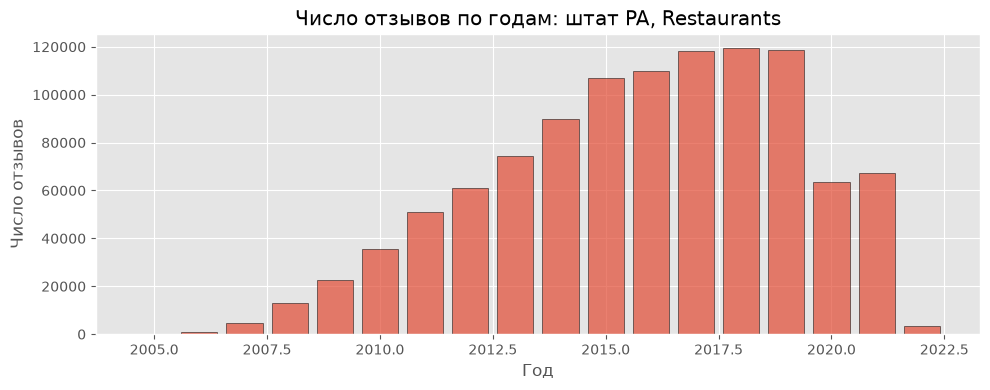

In [239]:
pool_yearly = (
    pool.group_by(pl.col("date").dt.year().alias("year"))
    .agg(pl.len().alias("n_reviews"))
    .sort("year")
)
print(pool_yearly)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(pool_yearly["year"].to_numpy(), pool_yearly["n_reviews"].to_numpy(), edgecolor="black", alpha=0.7)
ax.set_xlabel("Год")
ax.set_ylabel("Число отзывов")
ax.set_title(f"Число отзывов по годам: штат {STATE}, {CATEGORY}")
plt.tight_layout()
plt.show()

In [240]:
from datetime import datetime

CUTOFF_DATE = datetime(2020, 1, 1)

pool_before_cut = pool
pool = pool.filter(pl.col("date") < CUTOFF_DATE)

print(f"Отзывов до обрезки:    {pool_before_cut.height:,}")
print(f"Отзывов после обрезки: {pool.height:,} (удалено {pool_before_cut.height - pool.height:,})")
print(f"Период после обрезки:  {pool['date'].min()} — {pool['date'].max()}")

Отзывов до обрезки:    1,060,935
Отзывов после обрезки: 926,367 (удалено 134,568)
Период после обрезки:  2005-02-16 04:06:26 — 2019-12-31 23:57:55


### Пороги отсева

In [241]:
pool_user_counts = pool.group_by("user_id").len()["len"]
pool_item_counts = pool.group_by("business_id").len()["len"]


def threshold_values(counts: pl.Series) -> dict:
    return {
        "среднее": float(counts.mean()),
        "медиана": float(counts.median()),
        "15-й процентиль": float(counts.quantile(0.15, interpolation="nearest")),
    }


user_thresholds = threshold_values(pool_user_counts)
item_thresholds = threshold_values(pool_item_counts)

thresholds_table = pl.DataFrame([
    {
        "statistic": stat,
        "user_threshold": round(user_thresholds[stat], 2),
        "users_removed_share": round((pool_user_counts < user_thresholds[stat]).mean(), 4),
        "item_threshold": round(item_thresholds[stat], 2),
        "items_removed_share": round((pool_item_counts < item_thresholds[stat]).mean(), 4),
    }
    for stat in user_thresholds
])
print(thresholds_table)

shape: (3, 5)
┌─────────────────┬────────────────┬─────────────────────┬────────────────┬─────────────────────┐
│ statistic       ┆ user_threshold ┆ users_removed_share ┆ item_threshold ┆ items_removed_share │
│ ---             ┆ ---            ┆ ---                 ┆ ---            ┆ ---                 │
│ str             ┆ f64            ┆ f64                 ┆ f64            ┆ f64                 │
╞═════════════════╪════════════════╪═════════════════════╪════════════════╪═════════════════════╡
│ среднее         ┆ 3.39           ┆ 0.8158              ┆ 77.51          ┆ 0.7457              │
│ медиана         ┆ 1.0            ┆ 0.0                 ┆ 30.0           ┆ 0.4934              │
│ 15-й процентиль ┆ 1.0            ┆ 0.0                 ┆ 8.0            ┆ 0.1341              │
└─────────────────┴────────────────┴─────────────────────┴────────────────┴─────────────────────┘


### Границы временного разбиения

In [242]:
TEST_SHARE = 0.20
VAL_SHARE = 0.10

pool_dates = pool["date"].sort()
n_pool = pool_dates.len()
VAL_START = pool_dates[int(n_pool * (1 - TEST_SHARE - VAL_SHARE))]
TEST_START = pool_dates[int(n_pool * (1 - TEST_SHARE))]


def split_label() -> pl.Expr:
    """train - до VAL_START, validation - от VAL_START до TEST_START, test - от TEST_START."""
    return (
        pl.when(pl.col("date") >= TEST_START).then(pl.lit("test"))
        .when(pl.col("date") >= VAL_START).then(pl.lit("validation"))
        .otherwise(pl.lit("train"))
        .alias("split")
    )


def split_shares(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df.with_columns(split_label())
        .group_by("split").agg(pl.len().alias("n_reviews"))
        .with_columns((pl.col("n_reviews") / pl.col("n_reviews").sum()).round(4).alias("share"))
        .sort("split")
    )


print(f"Начало validation: {VAL_START}")
print(f"Начало test:       {TEST_START}")
print(split_shares(pool))

Начало validation: 2017-08-22 01:25:52
Начало test:       2018-06-08 23:34:48
shape: (3, 3)
┌────────────┬───────────┬───────┐
│ split      ┆ n_reviews ┆ share │
│ ---        ┆ ---       ┆ ---   │
│ str        ┆ u32       ┆ f64   │
╞════════════╪═══════════╪═══════╡
│ test       ┆ 185274    ┆ 0.2   │
│ train      ┆ 648456    ┆ 0.7   │
│ validation ┆ 92637     ┆ 0.1   │
└────────────┴───────────┴───────┘


### Сравнение вариантов

In [243]:
LIMITS = {"min_interactions": 100_000, "max_interactions": 2_000_000, "min_users": 1_000, "min_items": 1_000}
RELEVANT_MIN_STARS = 4


def eval_users(df: pl.DataFrame, history_end, eval_start, eval_end=None) -> int:
    """Пользователи с ≥1 оценкой до history_end и ≥1 релевантной оценкой в [eval_start, eval_end)."""
    if df.height == 0:
        return 0
    in_eval = pl.col("date") >= eval_start
    if eval_end is not None:
        in_eval = in_eval & (pl.col("date") < eval_end)
    per_user = df.group_by("user_id").agg(
        (pl.col("date") < history_end).sum().alias("n_history"),
        (in_eval & (pl.col("stars") >= RELEVANT_MIN_STARS)).sum().alias("n_relevant"),
    )
    return per_user.filter((pl.col("n_history") >= 1) & (pl.col("n_relevant") >= 1)).height


def describe(df: pl.DataFrame, **params) -> dict:
    n, n_u, n_i = df.height, df["user_id"].n_unique(), df["business_id"].n_unique()
    return {
        **params,
        "interactions": n,
        "users": n_u,
        "items": n_i,
        "density_%": round(100 * n / (n_u * n_i), 4) if n else 0.0,
        "median_per_user": float(df.group_by("user_id").len()["len"].median()) if n else 0.0,
        "share_stars>=4": round(df.select((pl.col("stars") >= 4).mean()).item(), 4) if n else 0.0,
        "item_matrix_gb": round(n_i ** 2 * 8 / 1e9, 2),
    }


def meets_limits(st: dict) -> bool:
    return (
        LIMITS["min_interactions"] <= st["interactions"] <= LIMITS["max_interactions"]
        and st["users"] >= LIMITS["min_users"]
        and st["items"] >= LIMITS["min_items"]
    )


def filter_once(df: pl.DataFrame, user_thr: float, item_thr: float) -> pl.DataFrame:
    """Один проход: оба условия проверяются по числам отзывов в исходной таблице df."""
    return df.filter(
        (pl.len().over("user_id") >= user_thr) & (pl.len().over("business_id") >= item_thr)
    )


def below_after(df: pl.DataFrame, user_thr: float, item_thr: float) -> tuple[float, float]:
    """Доли пользователей и заведений, у которых после фильтра отзывов меньше порога."""
    if df.height == 0:
        return 0.0, 0.0
    u = df.group_by("user_id").len()["len"]
    i = df.group_by("business_id").len()["len"]
    return round((u < user_thr).mean(), 4), round((i < item_thr).mean(), 4)


option_rows = []
for user_stat, user_thr in user_thresholds.items():
    for item_stat, item_thr in item_thresholds.items():
        filtered = filter_once(pool, user_thr, item_thr)
        row = describe(
            filtered,
            user_stat=user_stat, user_threshold=round(user_thr, 2),
            item_stat=item_stat, item_threshold=round(item_thr, 2),
        )
        row["users_below_after"], row["items_below_after"] = below_after(filtered, user_thr, item_thr)
        row["meets_limits"] = meets_limits(row)
        row["eval_users_test"] = eval_users(filtered, history_end=TEST_START, eval_start=TEST_START)
        row["eval_users_share"] = round(row["eval_users_test"] / row["users"], 4) if row["users"] else 0.0
        option_rows.append(row)
options_df = pl.DataFrame(option_rows)

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=300, fmt_str_lengths=20):
    print(options_df)

shape: (9, 16)
┌─────────────────┬────────────────┬─────────────────┬────────────────┬──────────────┬────────┬───────┬───────────┬─────────────────┬────────────────┬────────────────┬───────────────────┬───────────────────┬──────────────┬─────────────────┬──────────────────┐
│ user_stat       ┆ user_threshold ┆ item_stat       ┆ item_threshold ┆ interactions ┆ users  ┆ items ┆ density_% ┆ median_per_user ┆ share_stars>=4 ┆ item_matrix_gb ┆ users_below_after ┆ items_below_after ┆ meets_limits ┆ eval_users_test ┆ eval_users_share │
│ ---             ┆ ---            ┆ ---             ┆ ---            ┆ ---          ┆ ---    ┆ ---   ┆ ---       ┆ ---             ┆ ---            ┆ ---            ┆ ---               ┆ ---               ┆ ---          ┆ ---             ┆ ---              │
│ str             ┆ f64            ┆ str             ┆ f64            ┆ i64          ┆ i64    ┆ i64   ┆ f64       ┆ f64             ┆ f64            ┆ f64            ┆ f64               ┆ f64              

### Выбор варианта

In [244]:
valid = options_df.filter(pl.col("meets_limits"))
print(f"Вариантов, удовлетворяющих ограничениям задания: {valid.height} из {options_df.height}")

if valid.height == 0:
    raise ValueError("Ни один вариант не удовлетворяет ограничениям задания: требуется отдельное решение")

choice = valid.sort("eval_users_test", descending=True, maintain_order=True).row(0, named=True)
USER_STAT, ITEM_STAT = choice["user_stat"], choice["item_stat"]
USER_THRESHOLD, ITEM_THRESHOLD = user_thresholds[USER_STAT], item_thresholds[ITEM_STAT]
print(f"Выбрано: порог для пользователей - {USER_STAT} ({USER_THRESHOLD:.2f}), "
      f"порог для заведений - {ITEM_STAT} ({ITEM_THRESHOLD:.2f}); "
      f"пользователей, пригодных для оценки на test: {choice['eval_users_test']:,}")

Вариантов, удовлетворяющих ограничениям задания: 9 из 9
Выбрано: порог для пользователей - медиана (1.00), порог для заведений - 15-й процентиль (8.00); пользователей, пригодных для оценки на test: 21,434


### Итоговая подвыборка



In [245]:
interactions = (
    filter_once(pool, USER_THRESHOLD, ITEM_THRESHOLD)
    .select("user_id", "business_id", "stars", "date", "useful", "funny", "cool")
    .sort(["date", "user_id", "business_id"])
)

final_stats = describe(interactions, stage="итоговая подвыборка")
assert meets_limits(final_stats), f"Подвыборка не удовлетворяет ограничениям: {final_stats}"

users_below, items_below = below_after(interactions, USER_THRESHOLD, ITEM_THRESHOLD)
print(f"После однократного фильтра отзывов меньше порога: у {users_below:.2%} пользователей "
      f"и у {items_below:.2%} заведений")

stages = pl.DataFrame([
    describe(reviews, stage="исходные отзывы"),
    describe(reviews_clean, stage="после очистки"),
    describe(subsample_base, stage="пользователи из user.json"),
    describe(pool_before_cut, stage=f"штат {STATE}, {CATEGORY}"),
    describe(pool, stage=f"до {CUTOFF_DATE.date()}"),
    final_stats,
])
with pl.Config(tbl_cols=-1, tbl_width_chars=250, fmt_str_lengths=40):
    print(stages)

print(f"\nГраницы разбиения: validation с {VAL_START}, test с {TEST_START}")
print("Фактические доли в итоговой подвыборке:")
print(split_shares(interactions))
print(f"Пользователей, пригодных для оценки на test (история до начала test): "
      f"{eval_users(interactions, history_end=TEST_START, eval_start=TEST_START):,}")
print(f"Справочно - пользователей, пригодных для оценки на validation (история до начала validation): "
      f"{eval_users(interactions, history_end=VAL_START, eval_start=VAL_START, eval_end=TEST_START):,}")

interactions.write_parquet("data/interactions.parquet")
print("\nСохранено: data/interactions.parquet")

print(
    f"\nДля раздела «Объём данных»: {final_stats['interactions']:,} взаимодействий, "
    f"{final_stats['users']:,} пользователей, {final_stats['items']:,} заведений; "
    f"штат {STATE}, категория {CATEGORY}; пороги: пользователи - {USER_STAT} ({USER_THRESHOLD:.2f}), "
    f"заведения - {ITEM_STAT} ({ITEM_THRESHOLD:.2f}); "
    f"период {interactions['date'].min()} - {interactions['date'].max()}"
)

После однократного фильтра отзывов меньше порога: у 0.00% пользователей и у 0.00% заведений
shape: (6, 8)
┌───────────────────────────┬──────────────┬─────────┬────────┬───────────┬─────────────────┬────────────────┬────────────────┐
│ stage                     ┆ interactions ┆ users   ┆ items  ┆ density_% ┆ median_per_user ┆ share_stars>=4 ┆ item_matrix_gb │
│ ---                       ┆ ---          ┆ ---     ┆ ---    ┆ ---       ┆ ---             ┆ ---            ┆ ---            │
│ str                       ┆ i64          ┆ i64     ┆ i64    ┆ f64       ┆ f64             ┆ f64            ┆ f64            │
╞═══════════════════════════╪══════════════╪═════════╪════════╪═══════════╪═════════════════╪════════════════╪════════════════╡
│ исходные отзывы           ┆ 6990280      ┆ 1987929 ┆ 150346 ┆ 0.0023    ┆ 1.0             ┆ 0.6702         ┆ 180.83         │
│ после очистки             ┆ 6745760      ┆ 1987929 ┆ 150346 ┆ 0.0023    ┆ 1.0             ┆ 0.6714         ┆ 180.83         

### EDA итоговой подвыборки

Отзывов на пользователя: mean 3.38, median 1, max 968
Отзывов на заведение:    mean 88.70, median 39, max 5222
Доля оценок 4–5: 0.6639
shape: (15, 3)
┌──────┬───────────┬────────────┐
│ year ┆ n_reviews ┆ mean_stars │
│ ---  ┆ ---       ┆ ---        │
│ i32  ┆ u32       ┆ f64        │
╞══════╪═══════════╪════════════╡
│ 2005 ┆ 117       ┆ 3.949      │
│ 2006 ┆ 842       ┆ 3.969      │
│ 2007 ┆ 4525      ┆ 3.778      │
│ 2008 ┆ 12722     ┆ 3.672      │
│ 2009 ┆ 22267     ┆ 3.657      │
│ 2010 ┆ 35361     ┆ 3.675      │
│ 2011 ┆ 50644     ┆ 3.655      │
│ 2012 ┆ 60528     ┆ 3.644      │
│ 2013 ┆ 73708     ┆ 3.664      │
│ 2014 ┆ 89156     ┆ 3.732      │
│ 2015 ┆ 106326    ┆ 3.74       │
│ 2016 ┆ 109140    ┆ 3.754      │
│ 2017 ┆ 117290    ┆ 3.784      │
│ 2018 ┆ 118576    ┆ 3.793      │
│ 2019 ┆ 116709    ┆ 3.795      │
└──────┴───────────┴────────────┘


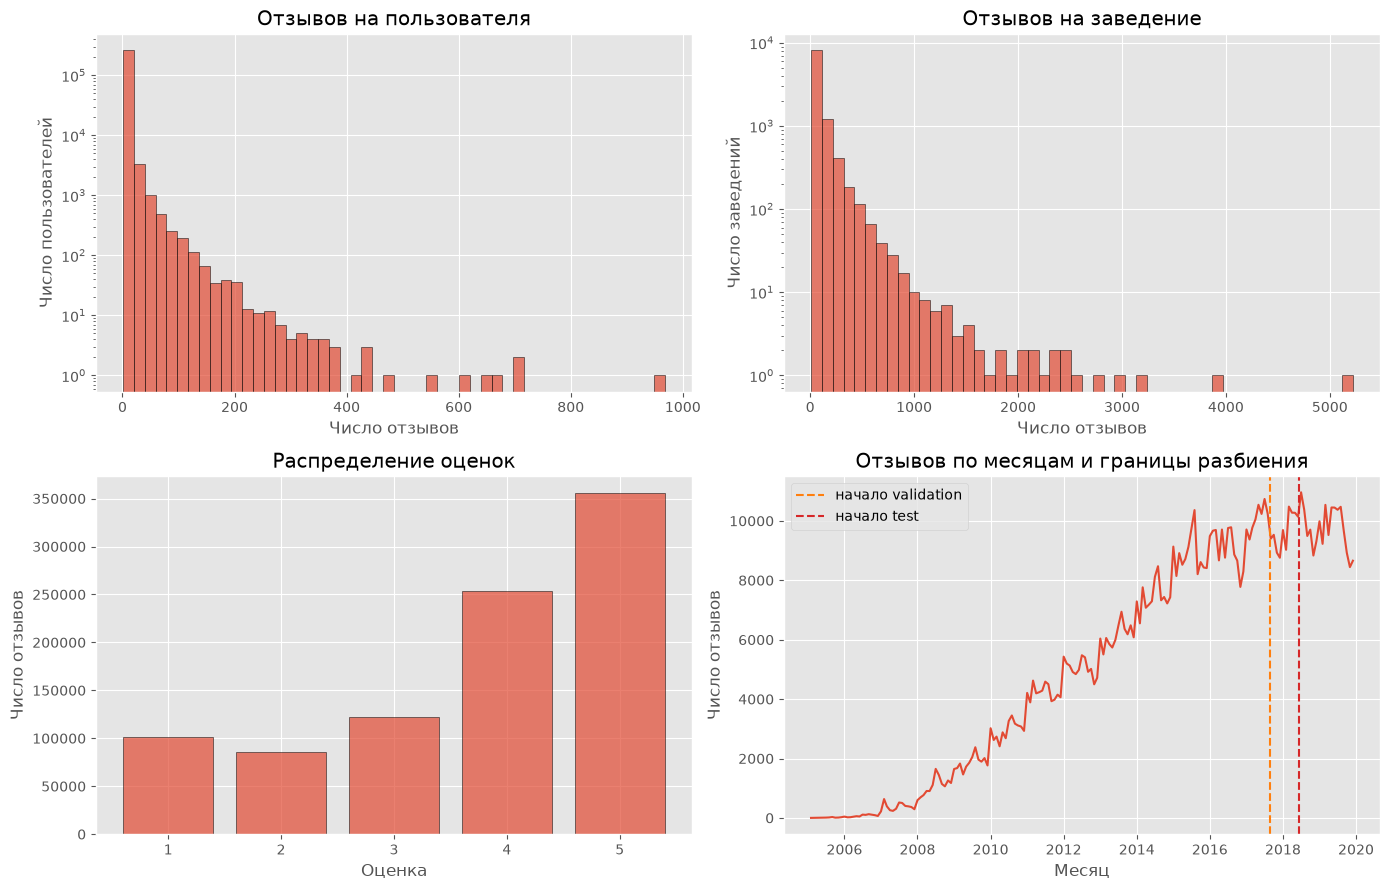

In [246]:
sub_user_counts = interactions.group_by("user_id").agg(pl.len().alias("n"))["n"]
sub_item_counts = interactions.group_by("business_id").agg(pl.len().alias("n"))["n"]
sub_stars = interactions.group_by("stars").agg(pl.len().alias("n")).sort("stars")
sub_yearly = (
    interactions.group_by(pl.col("date").dt.year().alias("year"))
    .agg(pl.len().alias("n_reviews"), pl.col("stars").mean().round(3).alias("mean_stars"))
    .sort("year")
)

print("Отзывов на пользователя: mean {:.2f}, median {:.0f}, max {}".format(
    sub_user_counts.mean(), sub_user_counts.median(), sub_user_counts.max()))
print("Отзывов на заведение:    mean {:.2f}, median {:.0f}, max {}".format(
    sub_item_counts.mean(), sub_item_counts.median(), sub_item_counts.max()))
print(f"Доля оценок 4–5: {(interactions['stars'] >= 4).mean():.4f}")
print(sub_yearly)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].hist(sub_user_counts.to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[0, 0].set_yscale("log")
axes[0, 0].set_xlabel("Число отзывов")
axes[0, 0].set_ylabel("Число пользователей")
axes[0, 0].set_title("Отзывов на пользователя")

axes[0, 1].hist(sub_item_counts.to_numpy(), bins=50, edgecolor="black", alpha=0.7)
axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("Число отзывов")
axes[0, 1].set_ylabel("Число заведений")
axes[0, 1].set_title("Отзывов на заведение")

axes[1, 0].bar(sub_stars["stars"].to_numpy(), sub_stars["n"].to_numpy(), edgecolor="black", alpha=0.7)
axes[1, 0].set_xlabel("Оценка")
axes[1, 0].set_ylabel("Число отзывов")
axes[1, 0].set_title("Распределение оценок")

sub_monthly = (
    interactions.group_by(pl.col("date").dt.truncate("1mo").alias("month"))
    .agg(pl.len().alias("n_reviews")).sort("month")
)
axes[1, 1].plot(sub_monthly["month"].to_numpy(), sub_monthly["n_reviews"].to_numpy())
axes[1, 1].axvline(VAL_START, color="tab:orange", linestyle="--", label="начало validation")
axes[1, 1].axvline(TEST_START, color="tab:red", linestyle="--", label="начало test")
axes[1, 1].set_xlabel("Месяц")
axes[1, 1].set_ylabel("Число отзывов")
axes[1, 1].set_title("Отзывов по месяцам и границы разбиения")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Протокол оценки


1. **Разбиение.** Будет два этапа: модель будет обучаться на train и валидироваться на val, а после этого будет финальное обучение на train + val и оценка на test. Глобальное по времени с датами `VAL_START` и `TEST_START` из раздела подвыборки: train — отзывы
   до `VAL_START`, validation — от `VAL_START` до `TEST_START`, test — от `TEST_START` (доли 70 / 10 / 20 %).
   *Почему:* timestamp есть, а глобальная граница гарантирует, что ни одна модель не видит взаимодействий позже
   границы.

2. **Этапы.** Подбор гиперпараметров: обучение на train, оценка на validation. Финальное сравнение: переобучение
   на train + validation с выбранными настройками, оценка на test.
   *Почему:* test используется только для финального сравнения после выбора настроек (п. 4 задания), а перед ним
   модель получает все данные до начала test.

3. **Релевантность.** Релевантный объект — заведение, которое пользователь оценил на 4–5 звёзд в окне оценки
   (validation или test). Множество релевантных включает все такие заведения пользователя в окне.

4. **Кандидаты.** Все заведения, у которых есть хотя бы один отзыв (с любой оценкой) в train:
   до `VAL_START` для validation, до `TEST_START` для test. Набор одинаков для всех моделей.
   *Почему:* коллаборативные модели могут оценить только заведения, встречавшиеся при обучении.

5. **Новые объекты.** Релевантные заведения окна, которых нет среди кандидатов, исключаются из множества
   релевантных; их доля выводится.

6. **Новые пользователи.** Пользователи без отзывов train в оценке не участвуют; их число
   выводится.
   *Почему:* без истории персональные рекомендации коллаборативными методами построить нельзя.

7. **Пользователи в оценке.** Пользователи, у которых есть хотя бы один отзыв в train и хотя бы одно
   релевантное заведение из набора кандидатов.

8. **Исключение известных объектов.** Из рекомендаций пользователя исключаются все заведения, которые он оценивал
   в обучающем периоде этапа, с любой оценкой.

9. **Повторные пары.** При очистке для каждой пары оставлен последний отзыв. Если у пары был и отзыв до начала окна,
   он удалён, и в окне заведение выглядит для пользователя новым. Такие пары остаются в оценке; их число и доля
   выводятся как ограничение.

10. **Длина списка.** K = 10

### Разбиение

In [247]:
interactions = interactions.with_columns(split_label())

split_summary = (
    interactions.group_by("split")
    .agg(
        pl.len().alias("n_reviews"),
        pl.col("user_id").n_unique().alias("n_users"),
        pl.col("business_id").n_unique().alias("n_items"),
        pl.col("date").min().alias("date_min"),
        pl.col("date").max().alias("date_max"),
    )
    .with_columns((pl.col("n_reviews") / pl.col("n_reviews").sum()).round(4).alias("share"))
    .sort("date_min")
)
with pl.Config(tbl_cols=-1, tbl_width_chars=200):
    print(split_summary)

shape: (3, 7)
┌────────────┬───────────┬─────────┬─────────┬─────────────────────┬─────────────────────┬────────┐
│ split      ┆ n_reviews ┆ n_users ┆ n_items ┆ date_min            ┆ date_max            ┆ share  │
│ ---        ┆ ---       ┆ ---     ┆ ---     ┆ ---                 ┆ ---                 ┆ ---    │
│ str        ┆ u32       ┆ u32     ┆ u32     ┆ datetime[μs]        ┆ datetime[μs]        ┆ f64    │
╞════════════╪═══════════╪═════════╪═════════╪═════════════════════╪═════════════════════╪════════╡
│ train      ┆ 643045    ┆ 185620  ┆ 9314    ┆ 2005-02-16 04:06:26 ┆ 2017-08-22 01:25:46 ┆ 0.7006 │
│ validation ┆ 91911     ┆ 46624   ┆ 7121    ┆ 2017-08-22 01:25:52 ┆ 2018-06-08 23:34:02 ┆ 0.1001 │
│ test       ┆ 182955    ┆ 86065   ┆ 7807    ┆ 2018-06-08 23:34:48 ┆ 2019-12-31 23:57:55 ┆ 0.1993 │
└────────────┴───────────┴─────────┴─────────┴─────────────────────┴─────────────────────┴────────┘


### Данные validation и test

Функция `build_stage` по границам формирует:

- `history` — обучающие взаимодействия;
- `candidates` — набор кандидатов;
- `ground_truth` — словарь «пользователь → множество релевантных заведений»;
- `seen` — словарь «пользователь → множество известных заведений»;
- `stats` — показатели для сводки.

In [248]:
def build_stage(df: pl.DataFrame, history_end, eval_start, eval_end=None, name: str = "") -> dict:
    history = df.filter(pl.col("date") < history_end)
    in_window = pl.col("date") >= eval_start
    if eval_end is not None:
        in_window = in_window & (pl.col("date") < eval_end)
    window = df.filter(in_window)

    candidates = history.select("business_id").unique()
    history_users = history.select("user_id").unique()

    relevant_all = window.filter(pl.col("stars") >= RELEVANT_MIN_STARS)
    relevant_cold = relevant_all.join(candidates, on="business_id", how="anti")
    relevant = (
        relevant_all
        .join(candidates, on="business_id", how="semi")
        .join(history_users, on="user_id", how="semi")
    )

    gt_df = relevant.group_by("user_id").agg(pl.col("business_id").alias("items"))
    ground_truth = {user: set(items) for user, items in gt_df.iter_rows()}

    seen_df = (
        history.join(gt_df.select("user_id"), on="user_id", how="semi")
        .group_by("user_id").agg(pl.col("business_id").alias("items"))
    )
    seen = {user: set(items) for user, items in seen_df.iter_rows()}

    overlap = sum(len(ground_truth[u] & seen.get(u, set())) for u in ground_truth)

    # Правило 9: у пары в исходных данных был отзыв до начала окна, удалённый при очистке
    earlier_pairs = reviews.filter(pl.col("date") < eval_start).select("user_id", "business_id").unique()
    gt_pairs = relevant.select("user_id", "business_id")
    repeated = gt_pairs.join(earlier_pairs, on=["user_id", "business_id"], how="semi").height

    new_users = window.select("user_id").unique().join(history_users, on="user_id", how="anti").height

    stats = {
        "history_interactions": history.height,
        "window_interactions": window.height,
        "candidates": candidates.height,
        "relevant_in_window": relevant_all.height,
        "relevant_new_items": relevant_cold.height,
        "relevant_new_items_share": round(relevant_cold.height / max(relevant_all.height, 1), 4),
        "new_users_in_window": new_users,
        "eval_users": len(ground_truth),
        "relevant_per_eval_user": round(gt_pairs.height / max(len(ground_truth), 1), 2),
        "repeated_pairs": repeated,
        "repeated_pairs_share": round(repeated / max(gt_pairs.height, 1), 4),
        "ground_truth_seen_overlap": overlap,
    }
    return {
        "name": name,
        "history": history,
        "candidates": candidates["business_id"].to_list(),
        "ground_truth": ground_truth,
        "seen": seen,
        "stats": stats,
    }


val_stage = build_stage(interactions, history_end=VAL_START, eval_start=VAL_START, eval_end=TEST_START,
                        name="validation")
test_stage = build_stage(interactions, history_end=TEST_START, eval_start=TEST_START, name="test")

for stage in (val_stage, test_stage):
    assert stage["stats"]["ground_truth_seen_overlap"] == 0, f"{stage['name']}: релевантные пересекаются с известными"
print("Проверка: релевантные заведения окна не пересекаются с известными — выполнена для обоих этапов")

Проверка: релевантные заведения окна не пересекаются с известными — выполнена для обоих этапов


### Сводка протокола

Таблица показывает объём обучающих данных и окна, число кандидатов, долю релевантных отзывов
о новых заведениях, число новых пользователей, число пользователей
в оценке и долю повторных пар. validation - обучение только на train, test - обучение на train + val.

In [249]:
def fmt(value):
    return f"{value:,}" if isinstance(value, int) else f"{value}"


protocol_summary = pl.DataFrame({
    "indicator": list(val_stage["stats"]),
    "validation": [fmt(v) for v in val_stage["stats"].values()],
    "test": [fmt(v) for v in test_stage["stats"].values()],
})
with pl.Config(tbl_rows=-1, fmt_str_lengths=40):
    print(protocol_summary)

shape: (12, 3)
┌───────────────────────────┬────────────┬─────────┐
│ indicator                 ┆ validation ┆ test    │
│ ---                       ┆ ---        ┆ ---     │
│ str                       ┆ str        ┆ str     │
╞═══════════════════════════╪════════════╪═════════╡
│ history_interactions      ┆ 643,045    ┆ 734,956 │
│ window_interactions       ┆ 91,911     ┆ 182,955 │
│ candidates                ┆ 9,314      ┆ 9,718   │
│ relevant_in_window        ┆ 62,115     ┆ 123,806 │
│ relevant_new_items        ┆ 6,154      ┆ 17,849  │
│ relevant_new_items_share  ┆ 0.0991     ┆ 0.1442  │
│ new_users_in_window       ┆ 28,177     ┆ 57,795  │
│ eval_users                ┆ 12,437     ┆ 18,872  │
│ relevant_per_eval_user    ┆ 2.34       ┆ 2.61    │
│ repeated_pairs            ┆ 943        ┆ 1,791   │
│ repeated_pairs_share      ┆ 0.0323     ┆ 0.0364  │
│ ground_truth_seen_overlap ┆ 0          ┆ 0       │
└───────────────────────────┴────────────┴─────────┘


# Обучение моделей, HPO и оценка

# Финальное сравнение

# Выводы